# RAG Pipeline Benchmarking vs Ground Truth

Evaluates the T21 Research Assistant pipeline answers against human-curated ground truth answers.

**Scientific Reports revision (v1):** re-run on the expanded 60-question benchmark set (30 positive-control
+ 30 negative-control questions, up from n=12) per reviewer feedback that the original benchmark size was
too small. Outputs are written to `output/ScientificReportRevisionV1/batch_eval/`, kept separate from the
original submission's `output/batch_eval/` results.

**Input:** `input/Revised_DownSyndrome_60_Questions_Final_linked.xlsx`
- `Original question` — question sent to the pipeline
- `Answer` — ground truth answer (human curated, semicolon-separated key points)
- `Citation` — optional citation

**Metrics computed per question:**
| Metric | Description |
|---|---|
| `semantic_sim` | Cosine similarity of llama-nemotron-embed-vl-1b-v2 embeddings (0–1) |
| `bertscore_p` | Sentence-level adapted BERTScore Precision — mean max-similarity of each candidate sentence to any reference sentence |
| `bertscore_r` | Sentence-level adapted BERTScore Recall — mean max-similarity of each reference sentence to any candidate sentence |
| `bertscore_f` | Sentence-level adapted BERTScore F — harmonic mean of Precision and Recall |

**Note on terminology:** the metric reported throughout this notebook is a **sentence-level adapted BERTScore**,
not the original token-level BERTScore (Zhang et al., 2020). It substitutes embedded-sentence cosine similarity
for token-level contextual embeddings, computed via `nvidia/llama-nemotron-embed-vl-1b-v2` (2048-dim) at sentence
granularity through the T21 `/embed_batch` API endpoint.
Two-pass sentence splitting: (1) split on `.!?` for prose; (2) split on `;` for GT key-point strings
that lack terminal punctuation. Precision and Recall are computed as the mean of maximum cosine
similarities across sentence pairs (mirrors the original BERTScore algorithm's max-similarity aggregation,
applied at sentence rather than token granularity).

**Embeddings:** `nvidia/llama-nemotron-embed-vl-1b-v2` (2048-dim) via `/embed_batch` — device auto-detected: **GPU (CUDA) if available, otherwise CPU**. Device is reported in the config cell output.


## Cell 2 — Config

In [1]:
import os
from pathlib import Path
from dotenv import load_dotenv
import pandas as pd

# ── Paths — notebook lives in analysis/nbs/, so '..' resolves to analysis/ ───
_NB_DIR  = Path('..').resolve()           # analysis/
BASE_DIR = _NB_DIR                        # alias
load_dotenv(BASE_DIR / '.env')            # analysis/.env

EXCEL_PATH = BASE_DIR / 'input' / 'Revised_DownSyndrome_60_Questions_Final_linked.xlsx'
# Scientific Reports revision (v1) — kept separate from the original submission's
# output/batch_eval/ results.
OUTPUT_DIR = BASE_DIR / 'output' / 'ScientificReportRevisionV1' / 'batch_eval'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_XLSX = OUTPUT_DIR / 'benchmark_results_JIM.xlsx'
RESULTS_JSON = OUTPUT_DIR / 'benchmark_results_JIM.json'

# API endpoints — T21 RAG + Nemotron embed (reuse model already loaded in API)
T21_API_URL         = os.getenv('T21_API_URL',         'http://localhost:8698/answer')
T21_EMBED_BATCH_URL = os.getenv('T21_EMBED_BATCH_URL', 'http://localhost:8698/embed_batch')

OPENAI_KEY    = os.getenv('OPENAI_API_KEY', '')
ANTHROPIC_KEY = os.getenv('ANTHROPIC_API_KEY', '')

# Models for comparator responses
OPENAI_MODEL    = os.getenv('OPENAI_CHAT_MODEL',    'gpt-5.4')
ANTHROPIC_MODEL = os.getenv('ANTHROPIC_CHAT_MODEL', 'claude-sonnet-4-6')

# Ollama / Nemotron chat settings (remote cloud)
OLLAMA_API_KEY        = os.getenv('OLLAMA_API_KEY', '')
OLLAMA_NEMOTRON_MODEL = os.getenv('OLLAMA_NEMOTRON_MODEL', 'nemotron-3-super')
OLLAMA_BASE_URL       = os.getenv('OLLAMA_REMOTE_BASE_URL', 'https://ollama.com')

TOP_K     = 20
MAX_WORDS = 150    # hard ceiling for all model responses (~150-word summaries)

# Rate limit (T21 API calls only — no per-call sleep for embed, handled by API)
API_SLEEP = 1.5   # seconds between T21 /answer calls

# ── T21 RAG run configuration ─────────────────────────────────────────────────
# section_mode="standard" → Results/Discussion/Methods/Conclusion only
#   (Abstract and Introduction are NOT retrieved — production default).
T21_SECTION_MODE  = "standard"   # no Abstract / Introduction

# ── Live API config detection (rerank_alpha + embed device) ───────────────────
# T21_RERANK_ALPHA is NOT passed explicitly in call_t21() — the API uses whatever
# RERANK_ALPHA is configured server-side in srv/.env at request time. Rather than
# hardcode a value here (which silently went stale after the section-condition
# sweep re-tuned it — see analysis/nbs/10_section_condition_analysis.ipynb), this
# is read live from /health on every run so it can never drift out of sync again.
import requests as _req_cfg

# ── Live collection gate (three-way: name + vectors + documents) ──────────────
# Fresh-results round 2026-09-06: the API must serve the article-only corpus.
EXPECTED_COLLECTION = 'DS_INCLUDE_2026_09_02_DEEPINFRA_2048'
EXPECTED_VECTORS    = 65_677
EXPECTED_DOCS       = 1_594
_hj = _req_cfg.get(T21_API_URL.replace('/answer', '/health'), timeout=30).json()
_hc = _hj['config']['milvus_collection']
_hv = int(str(_hj['database']['total_vectors']).replace(',', ''))
_hd = int(str(_hj['database']['estimated_documents']).replace(',', ''))
assert _hc == EXPECTED_COLLECTION, f'API serves {_hc!r}, expected {EXPECTED_COLLECTION!r}'
assert _hv == EXPECTED_VECTORS, f'API vectors {_hv:,} != expected {EXPECTED_VECTORS:,}'
assert _hd == EXPECTED_DOCS,    f'API documents {_hd:,} != expected {EXPECTED_DOCS:,}'
print(f'Collection gate OK: {_hc} ({_hv:,} vectors, {_hd:,} documents)')

T21_RERANK_ALPHA = None
_api_device = 'unknown'
try:
    _health = _req_cfg.get(T21_API_URL.replace('/answer', '/health'), timeout=10).json()
    T21_RERANK_ALPHA = _health.get('config', {}).get('rerank_alpha')
    _api_device = _health.get('config', {}).get('embed_device', 'unknown')
except Exception as _e:
    print(f'[WARN] Could not fetch live /health config: {_e}')

# ── Device detection (local notebook environment) ─────────────────────────────
try:
    import torch
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
    _gpu_name = torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'N/A'
except ImportError:
    DEVICE = 'cpu'
    _gpu_name = 'N/A (torch not installed)'

if not _api_device or _api_device == 'unknown':
    # Infer from NEMOTRON_DEVICE env var if health doesn't expose it
    _api_device = os.getenv('NEMOTRON_DEVICE', '') or ('cuda' if DEVICE == 'cuda' else 'cpu')

assert OPENAI_KEY,    'OPENAI_API_KEY not set in .env'
assert ANTHROPIC_KEY, 'ANTHROPIC_API_KEY not set in .env'
assert T21_RERANK_ALPHA is not None, \
    'Could not read rerank_alpha from /health — check T21_API_URL / API is up before proceeding'
print('Base dir          :', BASE_DIR)
print('Excel             :', EXCEL_PATH)
print('Output dir        :', OUTPUT_DIR)
print('T21 API           :', T21_API_URL)
print('T21 Embed batch   :', T21_EMBED_BATCH_URL, ' (llama-nemotron-embed-vl-1b-v2 2048-dim, server-side)')
print('OpenAI mdl        :', OPENAI_MODEL)
print('Claude mdl        :', ANTHROPIC_MODEL)
print('Nemotron chat mdl :', OLLAMA_NEMOTRON_MODEL, '(via', OLLAMA_BASE_URL + ')')
print('Results xlsx      :', RESULTS_XLSX)
print('top_k             :', TOP_K, '  max_words:', MAX_WORDS)
print(f'\n── T21 RAG Config ──────────────────────────────────────────────────────')
print(f'  RERANK_ALPHA    : {T21_RERANK_ALPHA}  (live from /health — not hardcoded)')
print(f'  section_mode    : {T21_SECTION_MODE}  (Results/Discussion/Methods/Conclusion only)')
print(f'\n── Device ─────────────────────────────────────────────────────────────')
print(f'  Notebook env    : {DEVICE.upper()}' + (f'  ({_gpu_name})' if DEVICE == 'cuda' else ''))
print(f'  API embed model : {_api_device.upper()}  (server-side, controls /embed_batch)')


Collection gate OK: DS_INCLUDE_2026_09_02_DEEPINFRA_2048 (65,677 vectors, 1,594 documents)
Base dir          : /path/to/project/T21_research_assistant_v7/analysis
Excel             : /path/to/project/T21_research_assistant_v7/analysis/input/Revised_DownSyndrome_60_Questions_Final_linked.xlsx
Output dir        : /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/batch_eval
T21 API           : http://localhost:8698/answer
T21 Embed batch   : http://localhost:8698/embed_batch  (llama-nemotron-embed-vl-1b-v2 2048-dim, server-side)
OpenAI mdl        : gpt-5.4
Claude mdl        : claude-sonnet-4-6
Nemotron chat mdl : nemotron-3-super (via https://ollama.com)
Results xlsx      : /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/batch_eval/benchmark_results_JIM.xlsx
top_k             : 20   max_words: 150

── T21 RAG Config ──────────────────────────────────────────────────────
  RERANK_ALPHA    : 0.8  (live from /health — 

## Cell 3 — Imports

In [2]:
import json, time, re, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from tqdm.auto import tqdm
from openai import OpenAI
from anthropic import Anthropic
from ollama import Client as OllamaClient

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)

openai_client    = OpenAI(api_key=OPENAI_KEY)
anthropic_client = Anthropic(api_key=ANTHROPIC_KEY)
ollama_client    = OllamaClient(
    host=OLLAMA_BASE_URL,
    headers={'Authorization': f'Bearer {OLLAMA_API_KEY}'},
)
print('Imports OK')
print(f'OpenAI   : {OPENAI_MODEL}')
print(f'Claude   : {ANTHROPIC_MODEL}')
print(f'Nemotron : {OLLAMA_NEMOTRON_MODEL}  @  {OLLAMA_BASE_URL}')


/home/user/anaconda3/envs/dschat/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imports OK
OpenAI   : gpt-5.4
Claude   : claude-sonnet-4-6
Nemotron : nemotron-3-super  @  https://ollama.com


In [3]:
"""
Pre-run cleanup — run this cell before executing the benchmark pipeline.
  1. Clears the T21 API in-memory response cache so no stale answers bleed in.
  2. Verifies the Nemotron /embed_batch endpoint is alive.
  3. Releases Python kernel memory (gc.collect).
"""
import gc
import requests as _cleanup_req

_T21_BASE = T21_API_URL.replace('/answer', '')

# ── 1. Clear T21 API response cache ───────────────────────────────────────────
try:
    _r = _cleanup_req.post(f'{_T21_BASE}/cache/clear', timeout=10)
    _r.raise_for_status()
    print(f'API cache cleared  : {_r.json()}')
except Exception as _e:
    print(f'Cache clear skipped: {_e}')

# ── 2. Verify /embed_batch is alive (llama-nemotron-embed-vl-1b-v2 stays loaded in API) ─────────
try:
    _r2 = _cleanup_req.post(
        T21_EMBED_BATCH_URL,
        json={'texts': ['warmup'], 'mode': 'document'},
        timeout=30,
    )
    _r2.raise_for_status()
    _d2 = _r2.json()
    print(f'Embed endpoint OK  : dim={_d2["dim"]}  (nvidia/llama-nemotron-embed-vl-1b-v2)')
except Exception as _e2:
    print(f'Embed endpoint WARN: {_e2}')

# ── 3. Release Python kernel memory ───────────────────────────────────────────
gc.collect()
print('gc.collect() done  : kernel memory released')


API cache cleared  : {'status': 'ok', 'message': 'Query cache cleared'}
Embed endpoint OK  : dim=2048  (nvidia/llama-nemotron-embed-vl-1b-v2)
gc.collect() done  : kernel memory released


## Cell 4 — Load benchmark questions & ground truth

In [4]:
df_bench = pd.read_excel(EXCEL_PATH, sheet_name='Questions_for_testing')
df_bench.columns = [c.strip() for c in df_bench.columns]

df_bench = df_bench.rename(columns={
    'Original question': 'question',
    'Answer'           : 'ground_truth',
    'Citation'         : 'citation',
    'CTRL_Type'        : 'ctrl_type',
})

# Keep all questions
df_bench = df_bench.dropna(subset=['question'])
df_bench['ground_truth'] = df_bench['ground_truth'].fillna('')
df_bench = df_bench.reset_index(drop=True)

# For negative controls the expected T21 response is the decline phrase.
# This becomes the ground truth so all models are evaluated against it.
_NEG_GT = (
    'No relevant information found in the available literature to answer this question.'
)
pos_mask = df_bench['ctrl_type'].str.strip().str.lower() == 'positive'
neg_mask = ~pos_mask
df_bench.loc[neg_mask & (df_bench['ground_truth'] == ''), 'ground_truth'] = _NEG_GT

print(f'Total questions     : {len(df_bench)}')
print(f'  Positive          : {pos_mask.sum()}')
print(f'  Negative (control): {neg_mask.sum()}')
print(f'\nNegative GT (expected decline):\n  "{_NEG_GT}"')
df_bench[['SLNo', 'ctrl_type', 'question', 'ground_truth']].head(8)


Total questions     : 60
  Positive          : 30
  Negative (control): 30

Negative GT (expected decline):
  "No relevant information found in the available literature to answer this question."


,SLNo,ctrl_type,question,ground_truth
0,Q1,Positive,Which clinical conditions are people with Down...,Individuals with Down syndrome are at high ris...
1,Q2,Positive,Which clinical conditions are people with Down...,Individuals with Down syndrome are at low risk...
2,Q3,Positive,Why do people with Down syndrome tend to have ...,"Four interferon receptors, IFNAR1, IFNAR2, IFN..."
3,Q4,Positive,Why are people with Down syndrome at high risk...,Amyloid Precursor Protein (APP) is located on ...
4,Q5,Positive,Do individuals with Down syndrome have overact...,Autoimmune thyroid dysfunction is highly preva...
5,Q6,Positive,Which interferon receptors are triplicated in ...,Four of the six interferon receptors are found...
6,Q7,Positive,How is Stat1 signaling affected in Down syndrome?,STAT1 signaling is generally increased due to ...
7,Q8,Positive,Which circulating immune cell is consistently ...,Individuals with Down syndrome have B cell lym...


## Cell 5 — Generate responses (T21 RAG, GPT, Claude, Nemotron)

**Resilient + resumable.** Checkpoints `responses_latest.csv`/`.json` to disk every
`_CHECKPOINT_EVERY` (default 5) questions, not just at the very end. On start, it also
reads any existing `responses_latest.csv` and **skips questions that already have all 4
model answers**, reusing the saved text instead of re-calling the APIs.

This closes a real gap from the first Scientific Reports revision run: the loop was
interrupted after ~20 of 30 questions (all 4 models simultaneously missing for the
remaining SLNo — the signature of a stopped loop, not 4 independent API failures), and
because nothing had been saved to disk yet, all of that partial progress was lost. If
this cell is interrupted now, simply re-run it — it will pick up exactly where it left
off rather than starting over.

**Critical bug fix (row-index cross-contamination):** an earlier version of this cell
built the generation loop from `df_bench[pos_mask].reset_index(drop=True)`, which
discards each row's true position in `df_bench` and renumbers the 30 positive-control
rows sequentially 0–29. Because positive and negative control questions are
**interleaved** in the source spreadsheet (e.g. Q1–12 positive, Q13–22 negative, Q23–39
positive, ...), the loop's `df_bench.at[row.name, ...]` writes silently landed on the
wrong row once the first block of negative controls was skipped — some answers were
written into negative-control rows (excluded from the saved CSV, so they appeared as
missing), and others overwrote a *different* positive question's row (e.g. SLNo 23's
saved answer was actually SLNo 33's COVID-19 answer). This was caught by spot-checking
saved rows against their own question text. The fix keeps `df_bench[pos_mask]`'s
original index intact and writes via `df_bench.at[idx, ...]` using that true index, so
every write lands on the correct row regardless of interleaving. All checkpoint data
generated before this fix was discarded (moved to
`output/ScientificReportRevisionV1/batch_eval/corrupted_backup/` for audit purposes,
not deleted) and the benchmark was regenerated from scratch.

In [5]:
import re as _re  # local alias used throughout this cell
import json, shutil
from datetime import datetime

# ── Constants ─────────────────────────────────────────────────────────────────
TOP_K_BASE    = TOP_K   # base retrieval count (from Cell 2)
TOP_K_MAX     = 30      # hard cap on dynamic boost
_GT_WC_FLOOR  = 80      # minimum target word count even if GT is very short
_CHECKPOINT_EVERY = 5   # save progress to disk every N questions (see resilience note below)

# ── Helper utilities (mirrors synthesizer_langchain + nb6) ───────────────────

_SENTENCE_END_RE    = _re.compile(r'[.!?]$')
_LIST_MARKER_RE     = _re.compile(r'^\d{1,2}[\.)]$')
_SPACE_BEFORE_PUNCT = _re.compile(r'\s+([.,;:!?])')
_ORPHAN_MARKER_RE   = _re.compile(r'(?:(?<=^)|(?<=\s))(?:[1-9]|1[0-2])(?=[.,;:!?](?:\s|$))')

def clean_response(text: str) -> str:
    text = str(text or '')
    text = _ORPHAN_MARKER_RE.sub('', text)
    text = _SPACE_BEFORE_PUNCT.sub(r'\1', text)
    text = _re.sub(r'\s{2,}', ' ', text)
    return text.strip()

def trim_to_sentences(text: str, max_words: int = MAX_WORDS) -> str:
    candidate = clean_response(text)
    if not candidate:
        return ''
    raw = _re.split(r'(?<=[.!?])\s+', candidate)
    complete = [s for s in raw
                if _SENTENCE_END_RE.search(s.strip()) and not _LIST_MARKER_RE.fullmatch(s.strip())]
    if not complete:
        return candidate
    result, count = [], 0
    for sent in complete:
        n = len(sent.split())
        if count + n > max_words:
            break
        result.append(sent)
        count += n
    return clean_response(' '.join(result) if result else complete[0])

def trim_to_gt_size(text: str, max_words: int, max_sents: int = 999) -> str:
    """Trim to at most max_words words AND max_sents sentences (whichever hits first).
    Used by Cell 5d _best_extract as a fallback — NOT called in the generation loop.
    All 4 models save full ~150-word outputs so Cell 5d has an equal-size pool.
    """
    candidate = clean_response(text)
    if not candidate:
        return ''
    raw = _re.split(r'(?<=[.!?])\s+', candidate)
    complete = [s for s in raw
                if _SENTENCE_END_RE.search(s.strip()) and not _LIST_MARKER_RE.fullmatch(s.strip())]
    if not complete:
        return candidate
    result, wc = [], 0
    for sent in complete:
        sw = len(sent.split())
        if wc + sw > max_words or len(result) >= max_sents:
            break
        result.append(sent)
        wc += sw
    return clean_response(' '.join(result) if result else complete[0])

def _count_sents(text: str) -> int:
    """Count complete sentences (≥3 words) — mirrors _split_sents from Cell 5d."""
    sents = [s.strip() for s in _re.split(r'(?<=[.!?])\s+', str(text).strip())
             if len(s.strip().split()) >= 3]
    return max(len(sents), 1)

def strip_quality_review(md: str) -> str:
    s = _re.sub(r'(?ims)^\s*#{1,6}\s*Quality\s+Review\s*\n.*?(?=^\s*#{1,6}\s*\S|\Z)', '', md)
    s = _re.sub(r'(?ims)^\s*Quality\s+Review\s*:?\s*\n.*?(?=^\s*#{1,6}\s*\S|\Z)', '', s)
    return _re.sub(r'\n{3,}', '\n\n', s).strip()

def extract_t21_answer(payload: dict) -> str:
    """Extract the # Summary section from a T21 API response.
    Strips all [PMCxxxxxxx:Section] citation markers for a fair text comparison.
    Returns the full cleaned prose (no word-count trimming applied here).
    """
    md = str(payload.get('markdown') or '')
    if md.strip():
        md = strip_quality_review(md)
        m = _re.search(r'#{1,2}\s*Summary[^\n]*\n(.*?)(?=\n#{1,2}\s|\Z)', md,
                       flags=_re.DOTALL | _re.IGNORECASE)
        txt = (m.group(1).strip() if m else md).strip()
        # Strip all citation markers so T21 text is citation-free for fair comparison
        txt = _re.sub(r'\s*\[{1,2}PMC\d{4,}:[A-Za-z0-9_-]+\]{1,2}(?:\([^)]+\))?', '', txt)
        txt = _re.sub(r'\[{1,2}PMC\d{4,}\]{1,2}(?:\([^)]+\))?', '', txt)
        return clean_response(txt)
    for k in ('answer', 'response', 'text', 'result'):
        v = str(payload.get(k) or '').strip()
        if v:
            return clean_response(v)
    return ''

# ── Dynamic top_k — mirrors synthesizer_langchain._get_dynamic_top_k ─────────

_COMPLEX_KEYWORDS = [
    'compare', 'versus', 'vs', 'difference', 'similar', 'contrast',
    'all', 'comprehensive', 'complete', 'overview', 'summarize',
    'how many', 'list', 'what are the', 'types of', 'categories',
    'mechanisms', 'pathways', 'treatments', 'therapies',
    'subgroups', 'subtypes', 'classification',
    'which', 'what conditions', 'what factors', 'what genes',
    'lower risk', 'higher risk', 'protective', 'risk factors',
    'associated with', 'related to', 'linked to',
]

def _get_dynamic_top_k(question: str, base_k: int = TOP_K_BASE, max_k: int = TOP_K_MAX) -> int:
    """Mirror of synthesizer_langchain._get_dynamic_top_k — same keyword list and boost rules."""
    q_lower = question.lower()
    boost = 0
    for kw in _COMPLEX_KEYWORDS:
        if kw in q_lower:
            boost = 5
            break
    if len(question) > 100:
        boost = max(boost, 3)
    if ' and ' in q_lower and len(question) > 50:
        boost = max(boost, 4)
    return min(base_k + boost, max_k)

# ── GT-length-adaptive prose system prompt (words + sentences) ───────────────
def _make_prose_system(max_words: int, max_sents: int = 5) -> str:
    return (
        'You are a biomedical research assistant specializing in Down syndrome (trisomy 21) research. '
        f'Write your answer as a continuous prose paragraph of exactly {max_sents} complete sentence(s) '
        f'and approximately {max_words} words. '
        'Do NOT use bullet points, numbered lists, bold headers, or markdown formatting. '
        'Do NOT include citations, references, or source markers of any kind. '
        'Do NOT open with a single-word answer such as "Yes." or "No." — begin directly with substantive information. '
        'Be factual, specific, and include quantitative data (percentages, effect sizes, sample sizes) where available. '
        'If the question is outside the scope of Down syndrome / Trisomy 21 research, '
        'state that clearly in one sentence.'
    )

# ── Model callers ─────────────────────────────────────────────────────────────

def _is_transient_t21_error(err_text: str) -> bool:
    t = str(err_text or '').lower()
    return (
        'timed out' in t or 'timeout' in t or 'connection' in t
        or 'read timeout' in t or '502' in t or '503' in t or '504' in t
    )

def call_t21(question: str, max_attempts: int = 4) -> tuple[str, dict]:
    """Call T21 RAG API with retry on transient errors.

    Sends the plain question — no budget text injected — so the key-term extractor
    never flags non-DS words from a prompt suffix.
    Timeout grows with each attempt: 900s → 960s → 1020s → 1080s (base 15 min).
    Returns (full_clean_summary_text, raw_payload).
    """
    top_k = _get_dynamic_top_k(question)
    for attempt in range(1, max_attempts + 1):
        timeout_s = 900 + (attempt - 1) * 60
        try:
            r = requests.post(
                T21_API_URL,
                json={'question': question, 'top_k': top_k, 'include_hits': True},
                timeout=timeout_s,
            )
            r.raise_for_status()
            payload = r.json()
            text = extract_t21_answer(payload)
            if attempt > 1:
                print(f'  [T21_OK] recovered on attempt {attempt}/{max_attempts}')
            return text, payload
        except requests.HTTPError as e:
            status = e.response.status_code if e.response is not None else 'NA'
            detail = e.response.text[:200] if e.response is not None else str(e)
            print(f'  [T21_WARN] HTTP {status}: {detail}')
            return '', {'error': str(e)}
        except Exception as e:
            err = str(e)
            if attempt < max_attempts and _is_transient_t21_error(err):
                sleep_s = 2 ** attempt + random.uniform(0, 1)
                print(f'  [T21_WARN] attempt {attempt}/{max_attempts} timed out; '
                      f'retrying in {sleep_s:.0f}s (next timeout={900 + attempt * 60}s)...')
                time.sleep(sleep_s)
                continue
            print(f'  [T21_FAIL] {err}')
            return '', {'error': err}
    return '', {'error': 'max retries exceeded'}

def call_openai(question: str, max_words: int = MAX_WORDS, max_sents: int = 5) -> str:
    try:
        r = openai_client.chat.completions.create(
            model=OPENAI_MODEL,
            messages=[
                {'role': 'system', 'content': _make_prose_system(max_words, max_sents)},
                {'role': 'user',   'content': question},
            ],
            temperature=0.2,
        )
        return (r.choices[0].message.content or '').strip()
    except Exception as e:
        return f'[OPENAI_ERROR] {e}'

def _is_transient_claude_error(err_text: str) -> bool:
    t = str(err_text or '').lower()
    return (
        'error code: 500' in t or 'internal server error' in t
        or "'type': 'api_error'" in t or 'overloaded' in t
        or 'rate limit' in t or '529' in t
    )

def call_claude(question: str, max_words: int = MAX_WORDS, max_sents: int = 5,
                max_attempts: int = 5) -> str:
    warned = False
    for attempt in range(1, max_attempts + 1):
        try:
            r = anthropic_client.messages.create(
                model=ANTHROPIC_MODEL,
                max_tokens=400,
                temperature=0.2,
                system=_make_prose_system(max_words, max_sents),
                messages=[{'role': 'user', 'content': question}],
            )
            result_text = (r.content[0].text or '').strip()
            if warned:
                print(f'  [CLAUDE_OK] recovered on attempt {attempt}/{max_attempts}')
            return result_text
        except Exception as e:
            err = str(e)
            if attempt < max_attempts and _is_transient_claude_error(err):
                sleep_s = 2 ** attempt + random.uniform(0, 1)
                print(f'  [CLAUDE_WARN] transient error attempt {attempt}/{max_attempts}; '
                      f'retrying in {sleep_s:.1f}s')
                time.sleep(sleep_s)
                warned = True
                continue
    return f'[CLAUDE_ERROR] max retries exceeded'

def call_nemotron(question: str, max_words: int = MAX_WORDS, max_sents: int = 5,
                  max_attempts: int = 6) -> str:
    for attempt in range(1, max_attempts + 1):
        try:
            full_text = ''
            for part in ollama_client.chat(
                model=OLLAMA_NEMOTRON_MODEL,
                messages=[
                    {'role': 'system', 'content': _make_prose_system(max_words, max_sents)},
                    {'role': 'user',   'content': question},
                ],
                stream=True,
                options={'temperature': 0.2},
            ):
                full_text += (part.message.content or '')
            return clean_response(full_text)
        except Exception as e:
            err = str(e)
            if attempt < max_attempts:
                # 429 rate limiting can persist for minutes when the key is shared with
                # the T21 API's own synthesis calls; back off much longer for it.
                if "429" in err or "too many concurrent" in err.lower():
                    sleep_s = min(120, 15 * attempt) + random.uniform(0, 3)
                else:
                    sleep_s = 2 ** attempt + random.uniform(0, 1)
                print(f'  [NEMOTRON_WARN] attempt {attempt}/{max_attempts}; '
                      f'retrying in {sleep_s:.1f}s — {err[:80]}')
                time.sleep(sleep_s)
                continue
            return f'[NEMOTRON_ERROR] {err}'
    return '[NEMOTRON_ERROR] max retries exceeded'

# ── Checkpoint save/resume helpers ────────────────────────────────────────────
# Resilience fix: the previous version of this cell only saved to disk in a
# separate cell (5b) AFTER the entire loop finished. When the run was
# interrupted partway through, everything already generated was lost because
# nothing had been written to disk yet. This now (a) checkpoints to disk every
# `_CHECKPOINT_EVERY` questions, and (b) on start, resumes from any prior
# responses_latest.csv — skipping questions that already have all 4 answers
# rather than re-calling every model from scratch.

def _to_sl_no(val, fallback: int) -> str:
    s = str(val).strip()
    return _re.sub(r'^[Qq]', '', s) if s else str(fallback)

def _save_checkpoint(note: str = '') -> int:
    """Write responses_latest.csv/.json (+ a timestamped copy) from df_bench's
    current in-memory state. Safe to call repeatedly. Returns count of rows
    that have all 4 model answers populated."""
    _ts = datetime.now().strftime('%Y%m%d_%H%M%S')
    _records = []
    for idx, row in df_bench[pos_mask].iterrows():
        raw_slno = row['SLNo'] if 'SLNo' in row.index else ''
        rec = {
            'sl_no'           : _to_sl_no(raw_slno, int(idx) + 1),
            'ctrl_type'       : str(row.get('ctrl_type', '')),
            'question'        : str(row.get('question', '')),
            'ground_truth'    : str(row.get('ground_truth', '')),
            'citation'        : str(row.get('citation', '')) if 'citation' in row.index else '',
            't21_answer'      : str(row.get('t21_answer', '') or ''),
            'gpt_answer'      : str(row.get('gpt_answer', '') or ''),
            'claude_answer'   : str(row.get('claude_answer', '') or ''),
            'nemotron_answer' : str(row.get('nemotron_answer', '') or ''),
            'generated_at'    : _ts,
        }
        for _i in range(1, 7):
            rec[f't21_retrieve_{_i}'] = str(row.get(f't21_retrieve_{_i}', '') or '')
        rec['t21_retrieve_meta'] = str(row.get('t21_retrieve_meta', '') or '[]')
        _records.append(rec)

    import os as _os
    _os.makedirs(OUTPUT_DIR, exist_ok=True)
    _ts_json = OUTPUT_DIR / f'responses_{_ts}.json'
    _ts_csv  = OUTPUT_DIR / f'responses_{_ts}.csv'
    with open(_ts_json, 'w', encoding='utf-8') as fh:
        json.dump({
            'generated_at'    : _ts,
            'openai_model'    : OPENAI_MODEL,
            'anthropic_model' : ANTHROPIC_MODEL,
            'nemotron_model'  : OLLAMA_NEMOTRON_MODEL,
            'top_k'           : TOP_K,
            'max_words'       : MAX_WORDS,
            'ctrl_type'       : 'positive only',
            'n_questions'     : len(_records),
            'responses'       : _records,
        }, fh, indent=2, ensure_ascii=False)
    _df_save = pd.DataFrame(_records)
    _df_save.to_csv(_ts_csv, index=False, encoding='utf-8-sig')
    shutil.copy2(_ts_json, OUTPUT_DIR / 'responses_latest.json')
    shutil.copy2(_ts_csv,  OUTPUT_DIR / 'responses_latest.csv')

    _n_complete = sum(
        1 for r in _records
        if r['t21_answer'] and r['gpt_answer'] and r['claude_answer'] and r['nemotron_answer']
    )
    _tag = f' ({note})' if note else ''
    print(f'  [checkpoint{_tag}] {_n_complete}/{len(_records)} complete rows saved -> responses_latest.csv')
    return _n_complete

# ── Resume: skip questions that already have all 4 answers from a prior run ───
# An answer containing an API-error marker does NOT count as complete (the RERUN2
# trap: 429 error strings were resumed as answers and reproduced contaminated numbers).
_ERR_MARKER_RESUME_RE = _re.compile(r'\[[A-Z][A-Z0-9_]*_ERROR\]|too many concurrent', _re.I)
_resume_map = {}
_resume_csv = OUTPUT_DIR / 'responses_latest.csv'
if _resume_csv.exists():
    try:
        _prev = pd.read_csv(_resume_csv)
        _prev.columns = [c.strip() for c in _prev.columns]
        for _, _r in _prev.iterrows():
            _sln  = _to_sl_no(_r.get('sl_no', ''), -1)
            _vals = {c: str(_r.get(c, '') or '') for c in
                     ['t21_answer', 'gpt_answer', 'claude_answer', 'nemotron_answer']}
            _vals = {k: ('' if v.lower() == 'nan' else v) for k, v in _vals.items()}
            if (_sln and all(_vals.values())
                    and not any(_ERR_MARKER_RESUME_RE.search(v) for v in _vals.values())):
                _entry = dict(_vals)
                for _i in range(1, 7):
                    _entry[f't21_retrieve_{_i}'] = str(_r.get(f't21_retrieve_{_i}', '') or '')
                _entry['t21_retrieve_meta'] = str(_r.get('t21_retrieve_meta', '') or '[]')
                _resume_map[_sln] = _entry
        if _resume_map:
            print(f'[RESUME] {len(_resume_map)} question(s) already complete in responses_latest.csv '
                  f'— will reuse instead of re-calling the models.')
    except Exception as _e:
        print(f'[RESUME] Could not read prior checkpoint, starting fresh: {_e}')

# ── Generate responses for POSITIVE CONTROL questions only ────────────────────
# BUG FIX (critical): this used to be
#     _df_gen = df_bench[pos_mask].reset_index(drop=True)
# which discards df_bench's TRUE row positions and renumbers the 30 positive
# rows 0..29 sequentially. Because positive/negative controls are INTERLEAVED
# in the source spreadsheet (e.g. Q1-12 positive, Q13-22 negative, Q23-39
# positive, ...), the loop below writes via `df_bench.at[idx, ...]` — with the
# reset index, `idx` (0..29) no longer matches each row's real position in
# df_bench once the first block of negatives is skipped. The result was
# silent cross-contamination: some rows never got a direct write (blank in
# the final CSV), and others received a DIFFERENT question's answer under
# their own question text (e.g. SLNo 23 "Are vaccines safe..." ended up
# holding SLNo 33's COVID-19 answer). Keeping the original index below makes
# `idx` from `.iterrows()` equal to df_bench's real row position, so every
# `.at[idx, ...]` write lands on the correct row regardless of interleaving.
_df_gen = df_bench[pos_mask]
print(f'Generating responses for {len(_df_gen)} positive-control questions '
      f'(skipping {neg_mask.sum()} negative controls).')
print(f'Models: T21 RAG  |  GPT ({OPENAI_MODEL})  |  '
      f'Claude ({ANTHROPIC_MODEL})  |  Nemotron ({OLLAMA_NEMOTRON_MODEL})')

t21_answers, t21_raws = [], []
gpt_answers, claude_answers, nemotron_answers = [], [], []
gt_word_counts = []
# Top-6 retrieved chunks from T21 RAG — saved for UMAP notebook (nb6)
t21_retrieve_texts = []   # list of [text1, text2, ..., text6] per question
t21_retrieve_metas = []   # list of JSON strings [{pmcid, section, score, title}×6]

for _seq, (idx, row) in enumerate(
        tqdm(_df_gen.iterrows(), total=len(_df_gen), desc='Generating (positive ctrl only)'),
        start=1):
    q      = row['question']
    gt     = str(row.get('ground_truth') or '')
    gt_wc  = max(_GT_WC_FLOOR, len(gt.split()))
    gt_sc  = _count_sents(gt)
    q_display = (q[:80] + '...') if len(q) > 80 else q
    _sln = _to_sl_no(row.get('SLNo', ''), _seq)

    if _sln in _resume_map:
        print(f'  [{_seq}/{len(_df_gen)}] [RESUME] SLNo {_sln} | {q_display}')
        _entry = _resume_map[_sln]
        t21_text, gpt_text = _entry['t21_answer'], _entry['gpt_answer']
        claude_text, nem_text = _entry['claude_answer'], _entry['nemotron_answer']
        t21_answers.append(t21_text); gpt_answers.append(gpt_text)
        claude_answers.append(claude_text); nemotron_answers.append(nem_text)
        t21_raws.append({})
        _chunks = [_entry.get(f't21_retrieve_{_ri}', '') for _ri in range(1, 7)]
        t21_retrieve_texts.append(_chunks)
        t21_retrieve_metas.append(_entry.get('t21_retrieve_meta', '[]'))
        for _ri, _ct in enumerate(_chunks, 1):
            df_bench.at[idx, f't21_retrieve_{_ri}'] = _ct
        df_bench.at[idx, 't21_retrieve_meta'] = _entry.get('t21_retrieve_meta', '[]')
        df_bench.at[idx, 't21_answer']      = t21_text
        df_bench.at[idx, 'gpt_answer']      = gpt_text
        df_bench.at[idx, 'claude_answer']   = claude_text
        df_bench.at[idx, 'nemotron_answer'] = nem_text
        gt_word_counts.append(gt_wc)
        continue

    print(f'  [{_seq}/{len(_df_gen)}] GT={gt_wc}w/{gt_sc}s | {q_display}')

    # ── T21 RAG ───────────────────────────────────────────────────────────────
    # Full natural output — no post-hoc word/sentence trimming.
    # Plain question sent (no budget text) so key-term extractor never rejects it.
    t21_text_raw, t21_raw = call_t21(q)
    t21_text = t21_text_raw          # intentionally NOT trimmed
    t21_answers.append(t21_text)
    t21_raws.append(t21_raw)

    # ── Extract top-6 retrieved chunks for UMAP (nb6) ─────────────────────────
    _hits = (t21_raw.get('raw_evidence') or []) if isinstance(t21_raw, dict) else []
    _chunks = [str(h.get('text', '')) for h in _hits[:6]]
    while len(_chunks) < 6:
        _chunks.append('')
    t21_retrieve_texts.append(_chunks)
    _meta_list = [
        {'pmcid': h.get('pmcid', ''), 'section': h.get('section', ''),
         'score': h.get('score',  0), 'title':   h.get('title',  '')}
        for h in _hits[:6]
    ]
    t21_retrieve_metas.append(json.dumps(_meta_list))
    for _ri, _ct in enumerate(_chunks, 1):
        df_bench.at[idx, f't21_retrieve_{_ri}'] = _ct
    df_bench.at[idx, 't21_retrieve_meta'] = json.dumps(_meta_list)
    df_bench.at[idx, 't21_answer']         = t21_text
    print(f'    T21  : {len(t21_text.split()):3d}w  {t21_text[:80]}')

    # ── GPT ───────────────────────────────────────────────────────────────────
    # Fixed MAX_WORDS budget — same cap as T21's natural output.
    gpt_text = call_openai(q, max_words=gt_wc, max_sents=gt_sc)
    gpt_answers.append(gpt_text)
    df_bench.at[idx, 'gpt_answer'] = gpt_text
    print(f'    GPT  : {len(gpt_text.split()):3d}w  {gpt_text[:80]}')

    # ── Claude ────────────────────────────────────────────────────────────────
    claude_text = call_claude(q, max_words=gt_wc, max_sents=gt_sc)
    claude_answers.append(claude_text)
    df_bench.at[idx, 'claude_answer'] = claude_text
    print(f'    CLD  : {len(claude_text.split()):3d}w  {claude_text[:80]}')

    # ── Nemotron ──────────────────────────────────────────────────────────────
    nem_text = call_nemotron(q, max_words=gt_wc, max_sents=gt_sc)
    nemotron_answers.append(nem_text)
    df_bench.at[idx, 'nemotron_answer'] = nem_text
    print(f'    NEM  : {len(nem_text.split()):3d}w  {nem_text[:80]}')

    gt_word_counts.append(gt_wc)
    time.sleep(API_SLEEP)

    # ── Incremental checkpoint — survives an interruption on the NEXT question ──
    if _seq % _CHECKPOINT_EVERY == 0:
        _save_checkpoint(note=f'{_seq}/{len(_df_gen)}')

print(f'\nDone — {len(t21_answers)} positive-control questions processed.')
_wc_t21 = sum(len(a.split()) for a in t21_answers) / max(len(t21_answers), 1)
_wc_gpt = sum(len(a.split()) for a in gpt_answers)  / max(len(gpt_answers),  1)
_wc_cld = sum(len(a.split()) for a in claude_answers) / max(len(claude_answers), 1)
_wc_nem = sum(len(a.split()) for a in nemotron_answers) / max(len(nemotron_answers), 1)
print(f'Mean word counts — T21: {_wc_t21:.0f} | GPT: {_wc_gpt:.0f} '
      f'| Claude: {_wc_cld:.0f} | Nemotron: {_wc_nem:.0f}')

# ── Final checkpoint (Cell 5b below also saves — this guarantees nothing is
#    lost even if Cell 5b is never run) ────────────────────────────────────────
_save_checkpoint(note='final')

Generating responses for 30 positive-control questions (skipping 30 negative controls).
Models: T21 RAG  |  GPT (gpt-5.4)  |  Claude (claude-sonnet-4-6)  |  Nemotron (nemotron-3-super)


Generating (positive ctrl only):   0%|          | 0/30 [00:00<?, ?it/s]

  [1/30] GT=80w/1s | Which clinical conditions are people with Down syndrome at higher risk for?
    T21  : 119w  Trisomy 21 creates a broad spectrum of health challenges that extend beyond the 
    GPT  :  80w  People with Down syndrome have elevated lifetime risks for multiple medical cond
    CLD  : 124w  People with Down syndrome face significantly elevated risks across multiple orga
    NEM  :  77w  Individuals with Down syndrome have a markedly increased prevalence of congenita


Generating (positive ctrl only):   3%|▎         | 1/30 [03:23<1:38:22, 203.53s/it]

  [2/30] GT=80w/1s | Which clinical conditions are people with Down syndrome at lower risk for?
    T21  : 100w  Individuals with Down syndrome (DS) exhibit a distinct comorbidity profile with 
    GPT  :  99w  Compared with the general population, people with Down syndrome appear to have s
    CLD  :  94w  People with Down syndrome exhibit a notably reduced risk of several clinical con
    NEM  :  80w  Individuals with Down syndrome have a markedly reduced risk of many solid tumors


...

Generating (positive ctrl only):  97%|█████████▋| 29/30 [55:53<01:12, 72.35s/it]

  [30/30] GT=127w/5s | Are oxygen-related processes dysregulated in Down syndrome, and is this driven b...
    T21  :  76w  Oxygen-related processes are dysregulated in Down syndrome (DS), with evidence o
    GPT  : 164w  Oxygen-related processes are frequently dysregulated in Down syndrome, with many
    CLD  : 187w  Oxidative stress is a well-documented feature of trisomy 21, with individuals sh
    NEM  : 126w  Oxygen homeostasis is disrupted in Down syndrome, with cells exhibiting signific


Generating (positive ctrl only): 100%|██████████| 30/30 [57:00<00:00, 114.01s/it]

  [checkpoint (30/30)] 30/30 complete rows saved -> responses_latest.csv

Done — 30 positive-control questions processed.
Mean word counts — T21: 96 | GPT: 125 | Claude: 134 | Nemotron: 98
  [checkpoint (final)] 30/30 complete rows saved -> responses_latest.csv


30

## Cell 5b — Verify checkpoint completeness

Cell 5 now saves its own checkpoints (incrementally + a final save), so this cell no
longer duplicates that logic — it re-reads `responses_latest.csv` and reports whether
every positive-control question has an answer from all 4 models. If any are still
missing, it lists their SLNo and tells you to just re-run Cell 5 (which will resume,
not restart from scratch).

In [9]:
"""
Verification cell — Cell 5 already saved responses_latest.csv/.json via
_save_checkpoint() (incrementally every _CHECKPOINT_EVERY questions, plus a
final save at the end), so this cell no longer duplicates that save logic —
it just re-reads what was written and reports whether the run is complete.

Files written by Cell 5's _save_checkpoint():
─────────────────────────────────────────────
• responses_<timestamp>.json   - full record per question (one per checkpoint)
• responses_<timestamp>.csv    - flat table (one per checkpoint)
• responses_latest.json        - always-overwritten latest copy
• responses_latest.csv         - always-overwritten latest flat CSV

Columns t21_retrieve_1 … t21_retrieve_6 contain the top-6 retrieved chunk
texts from the T21 RAG pipeline for each question — used by notebook 4 (UMAP).
t21_retrieve_meta is a JSON list of {pmcid, section, score, title} for each chunk.
"""
_latest_csv = OUTPUT_DIR / 'responses_latest.csv'
if not _latest_csv.exists():
    raise FileNotFoundError(
        f'{_latest_csv} not found — Cell 5 must run (or at least reach its first '
        f'checkpoint) before this verification cell.'
    )

_df_save = pd.read_csv(_latest_csv)
_df_save.columns = [c.strip() for c in _df_save.columns]
_answer_cols = ['t21_answer', 'gpt_answer', 'claude_answer', 'nemotron_answer']
for _c in _answer_cols:
    _df_save[_c] = _df_save[_c].fillna('').astype(str)
    _df_save.loc[_df_save[_c].str.lower() == 'nan', _c] = ''

_complete_mask = _df_save[_answer_cols].apply(lambda c: c.str.len() > 0).all(axis=1)
_n_complete = int(_complete_mask.sum())
_n_total    = len(_df_save)

print(f'Checkpoint file    : {_latest_csv}')
print(f'Rows complete      : {_n_complete} / {_n_total}')

if _n_complete < _n_total:
    _missing_slnos = _df_save.loc[~_complete_mask, 'sl_no'].astype(str).tolist()
    print(f'\n[INCOMPLETE] {_n_total - _n_complete} question(s) still missing an answer '
          f'from at least one model — SLNo: {", ".join(_missing_slnos)}')
    print('Re-run Cell 5 to resume: it will automatically skip the already-complete '
          'questions above and only re-call the models for the missing ones.')
else:
    print('\n✓ All positive-control questions have answers from all 4 models. Ready to score.')

# ── Retrieve coverage ─────────────────────────────────────────────────────────
_n_ret = int((_df_save['t21_retrieve_1'].fillna('').astype(str).str.len() > 0).sum())
print(f'\nT21 retrieve columns  : t21_retrieve_1 … t21_retrieve_6 + t21_retrieve_meta')
print(f'  Questions with ≥1 chunk: {_n_ret} / {_n_total}')

# ── Word count summary ────────────────────────────────────────────────────────
_wc = _df_save[_answer_cols].apply(lambda c: c.apply(lambda x: len(str(x).split())))
print('\nWord count (mean, complete rows only):',
      ' | '.join(f'{c.replace("_answer","")}: {_wc.loc[_complete_mask, c].mean():.0f}'
                  for c in _wc.columns) if _n_complete else '(no complete rows yet)')
_df_save[['sl_no','ctrl_type','question',
          't21_answer','gpt_answer','claude_answer','nemotron_answer',
          't21_retrieve_1','t21_retrieve_meta']].head(4)


Checkpoint file    : /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/batch_eval/responses_latest.csv
Rows complete      : 30 / 30

✓ All positive-control questions have answers from all 4 models. Ready to score.

T21 retrieve columns  : t21_retrieve_1 … t21_retrieve_6 + t21_retrieve_meta
  Questions with ≥1 chunk: 30 / 30

Word count (mean, complete rows only): t21: 96 | gpt: 125 | claude: 134 | nemotron: 98


,sl_no,ctrl_type,question,t21_answer,gpt_answer,claude_answer,nemotron_answer,t21_retrieve_1,t21_retrieve_meta
0,1,Positive,Which clinical conditions are people with Down...,Trisomy 21 creates a broad spectrum of health ...,People with Down syndrome have elevated lifeti...,People with Down syndrome face significantly e...,Individuals with Down syndrome have a markedly...,". Not surprisingly, patients with Down syndrom...","[{""pmcid"": ""PMC9796221"", ""section"": ""Results"",..."
1,2,Positive,Which clinical conditions are people with Down...,Individuals with Down syndrome (DS) exhibit a ...,"Compared with the general population, people w...",People with Down syndrome exhibit a notably re...,Individuals with Down syndrome have a markedly...,". Not surprisingly, patients with Down syndrom...","[{""pmcid"": ""PMC9796221"", ""section"": ""Results"",..."
2,3,Positive,Why do people with Down syndrome tend to have ...,Trisomy 21 (T21) leads to overexpression of im...,People with Down syndrome often show chronic i...,People with Down syndrome exhibit chronic immu...,Trisomy 21 causes a dosage imbalance of chromo...,Down syndrome is characterized by signs of aty...,"[{""pmcid"": ""PMC9777448"", ""section"": ""Results"",..."
3,4,Positive,Why are people with Down syndrome at high risk...,Trisomy 21 (T21) causes Down syndrome (DS) and...,People with Down syndrome are at high risk for...,People with Down syndrome carry three copies o...,People with Down syndrome have three copies of...,Trisomy 21 causes Down syndrome (DS) and is a ...,"[{""pmcid"": ""PMC12344623"", ""section"": ""Results""..."


## Cell 9 — Per-question & Summary Visualisation (Positive Control Only)

Two figures comparing the four models across all positive-control questions:

1. **Per-question grouped bar chart** — BERTScore Precision, Recall, F, and Semantic Similarity plotted side-by-side for each question (Q1–Qn). A single dark-gray dashed line marks the **overall grand average** across all models and questions for each metric.

2. **Mean ± SD summary horizontal bar chart** — aggregate performance across all positive-control questions, with error bars showing the standard deviation.

**Model order:** T21 RAG | Nemotron-3-Super | GPT-5.4 | Claude Sonnet 4.6

**Colours:** colour-blind-safe palette (Okabe–Ito derived) — T21 RAG blue (`#0072B2`), Nemotron vermillion (`#D55E00`), GPT-5.4 orange (`#E69F00`), Claude reddish-purple (`#CC79A7`). Replaces the original NPG (Nature Publishing Group) palette, which paired Nemotron (crimson red) with GPT-5.4 (emerald green) in the same chart — reviewer feedback flagged this as inaccessible to common colour vision deficiencies and carrying an unintended "red = bad, green = good" connotation.

**Output files saved to `output/ScientificReportRevisionV1/batch_eval/`:** `.pdf`, `.jpg`, `.tiff` — summary charts at 600 dpi; per-question charts at 600 dpi (PDF, vector) / 200 dpi (JPG, TIFF — capped to keep raster file sizes reasonable at n=30 questions, see Cell 9 code comment).

## Standalone shortcut — load from responses_latest.csv, skip generation

Run **only** cells 2 (Config) and 3 (Imports) first, then run the two cells below.  
No LLM generation needed — reads saved responses from `responses_latest.csv`, then recomputes BERTScore and Semantic Similarity metrics via `/embed_batch` before producing the visualisation.


In [10]:
"""
Shortcut loading cell — reads responses_latest.csv and recomputes BERTScore
and Semantic Similarity via /embed_batch (llama-nemotron-embed-vl-1b-v2, 2048-dim).
Run this cell AFTER the Config (cell 2) and Imports (cell 3) cells.
Then run the visualisation cell below.
"""
import re as _re_sc
import numpy as np
import requests as _req_sc
import pandas as pd

# ── Load checkpoint ────────────────────────────────────────────────────────────
_csv_path = OUTPUT_DIR / 'responses_latest.csv'
if not _csv_path.exists():
    raise FileNotFoundError(
        f'responses_latest.csv not found at {_csv_path}. '
        'Run the full pipeline (cells 5 → 5b) first to generate it.'
    )

df_bench = pd.read_csv(_csv_path)
df_bench.columns = [c.strip() for c in df_bench.columns]

# Recreate pos_mask
_ct_col = 'ctrl_type' if 'ctrl_type' in df_bench.columns else None
if _ct_col:
    pos_mask = df_bench[_ct_col].str.strip().str.lower() == 'positive'
else:
    pos_mask = pd.Series([True] * len(df_bench), index=df_bench.index)

print(f'Loaded {len(df_bench)} rows from {_csv_path}')
print(f'  Positive control : {pos_mask.sum()}')
print(f'  Negative control : {(~pos_mask).sum()}')

# ── NaN-safety pass — guard against incomplete generation runs ────────────────
# If Cell 5's generation loop was interrupted before finishing all questions,
# the unwritten rows come back from CSV as real NaN floats (pandas parses the
# literal text "nan" back to NaN on reload). Passing a raw NaN into a JSON
# request body crashes with `ValueError: Out of range float values are not
# JSON compliant` inside requests — this pass converts every missing answer
# to an empty string first, so scoring degrades gracefully (an empty answer
# just scores 0 for that row) instead of crashing the whole cell.
_ANSWER_COLS = ['ground_truth', 't21_answer', 'gpt_answer', 'claude_answer', 'nemotron_answer']
for _col in _ANSWER_COLS:
    if _col in df_bench.columns:
        df_bench[_col] = df_bench[_col].fillna('').astype(str)
        df_bench.loc[df_bench[_col].str.lower() == 'nan', _col] = ''

_missing_report = {
    _col: sorted(df_bench.loc[pos_mask & (df_bench[_col] == ''), 'sl_no'].astype(str).tolist())
    for _col in ['t21_answer', 'gpt_answer', 'claude_answer', 'nemotron_answer']
    if _col in df_bench.columns
}
_any_missing = any(_missing_report.values())
if _any_missing:
    print('\n[WARN] Missing (empty/never-generated) answers detected — these rows are EXCLUDED')
    print('       from scoring (NaN, dropped from the mean), never scored as 0. Re-run Cell 5')
    print('       (generation) to fill them in before quoting final numbers:')
    for _col, _slnos in _missing_report.items():
        if _slnos:
            print(f'  {_col:16s}: SLNo {", ".join(_slnos)}  ({len(_slnos)} missing)')

# ── Strip residual PMC citation tokens from t21_answer ────────────────────────
_PMC_TOK_RE_SC = _re_sc.compile(r'\s*\[{1,2}PMC\d{4,}[^\]]*\]{1,2}(?:\([^)]*\))?')
df_bench.loc[pos_mask, 't21_answer'] = (
    df_bench.loc[pos_mask, 't21_answer'].fillna('').apply(
        lambda x: _re_sc.sub(r'\s{2,}', ' ', _PMC_TOK_RE_SC.sub('', x)).strip()
    )
)

# ── BERTScore helpers (mirrors Cell 6) ────────────────────────────────────────
# Standing rule: empty answers and API-error marker responses are EXCLUDED from
# scoring (NaN, dropped from means) - never scored as 0 and never embedded.
_ERR_MARKER_RE_SC = _re_sc.compile(r'\[[A-Z][A-Z0-9_]*_ERROR\]|too many concurrent', _re_sc.I)

def _is_invalid_answer_sc(text) -> bool:
    t = str(text or '').strip()
    return (not t) or t.lower() == 'nan' or bool(_ERR_MARKER_RE_SC.search(t))

_SENT_RE_SC = _re_sc.compile(r'(?<=[.!?])\s+')
_SEMI_RE_SC = _re_sc.compile(r'\s*;\s*')
# Comma-enumeration splitter — fallback for chunks with no semicolons at all.
# Handles "X, Y, Z, and W" / "X, Y, Z and W" list patterns.
_LIST_COMMA_RE = _re_sc.compile(r',\s*(?:and\s+)?|\s+and\s+')

def _split_sents_sc(text):
    """Split reference/candidate text into semantic units for sentence-level BERTScore.

    Scientific Reports revision (v1) fix: the revised 60-question benchmark's ground-truth
    answers are written as flowing prose (e.g. "X are at high risk for A, B, C, ... and D"),
    not the original dataset's semicolon-separated key-point format. Without this fix, a
    9-item enumeration with zero semicolons and zero terminal punctuation collapses into ONE
    diffuse reference "sentence" blending all 9 concepts — which cannot closely match any
    single focused sentence from a real model answer, uniformly suppressing BERTScore across
    ALL models (observed: F1 ~0.31-0.35 for every model vs. the original ~0.60, with no model
    scoring differently from another — the signature of a broken measurement, not a real
    answer-quality regression). This adds a comma-enumeration fallback so an unpunctuated list
    still splits into individual key points, restoring the metric's intended behavior.
    """
    raw = _SENT_RE_SC.split(str(text or '').strip())
    result = []
    for chunk in raw:
        chunk = chunk.strip()
        if not chunk:
            continue
        ends_terminal = bool(_re_sc.search(r'[.!?]\s*$', chunk))
        if not ends_terminal and ';' in chunk:
            parts = [p.strip() for p in _SEMI_RE_SC.split(chunk) if p.strip()]
            result.extend(parts)
        elif not ends_terminal and chunk.count(',') >= 2:
            # No semicolons but a genuine comma-enumerated list (>=3 items) — split on
            # commas / "and" so each item becomes its own reference/candidate unit instead
            # of one blended embedding.
            parts = [p.strip() for p in _LIST_COMMA_RE.split(chunk) if p.strip()]
            result.extend(parts if len(parts) > 1 else [chunk])
        else:
            result.append(chunk)
    return result

def _embed_batch_sc(texts):
    # Extra safety net: guarantee every element is a plain string before this
    # ever reaches json.dumps (requests raises ValueError on a raw NaN/float).
    texts = [str(t) if t is not None else '' for t in texts]
    texts = ['no content' if not t.strip() else t for t in texts]
    r = _req_sc.post(
        T21_EMBED_BATCH_URL,
        json={'texts': texts, 'mode': 'document'},
        timeout=180,
    )
    r.raise_for_status()
    return np.array(r.json()['embeddings'], dtype=np.float32)

def _bertscore_sc(reference, candidate):
    # NaN (excluded from the mean), not 0: an empty/unsplittable side means
    # "cannot score", and a 0 would wrongly drag that model's mean down.
    _default = {'bertscore_p': float('nan'), 'bertscore_r': float('nan'),
                'bertscore_f': float('nan')}
    ref_sents  = _split_sents_sc(reference)
    cand_sents = _split_sents_sc(candidate)
    if not ref_sents or not cand_sents:
        return _default
    try:
        vecs  = _embed_batch_sc(ref_sents + cand_sents)
        norms = np.linalg.norm(vecs, axis=1, keepdims=True)
        vecs  = vecs / np.maximum(norms, 1e-9)
        sim   = vecs[:len(ref_sents)] @ vecs[len(ref_sents):].T
        recall    = float(sim.max(axis=1).mean())
        precision = float(sim.max(axis=0).mean())
        f1        = (2*precision*recall/(precision+recall)
                     if precision+recall > 0 else 0.0)
        return {'bertscore_p': round(precision, 4),
                'bertscore_r': round(recall,    4),
                'bertscore_f': round(f1,        4)}
    except Exception as exc:
        print(f'  [bertscore_err] {exc}')
        return {k: float('nan') for k in _default}

# ── Compute BERTScore — positive controls only ────────────────────────────────
df_bench_pos = df_bench[pos_mask].copy()
print(f'\nComputing BERTScore on {len(df_bench_pos)} positive-control questions...')
for model, col in [('t21',      't21_answer'),
                   ('gpt',      'gpt_answer'),
                   ('claude',   'claude_answer'),
                   ('nemotron', 'nemotron_answer')]:
    df_bench[f'{model}_bertscore_p'] = float('nan')
    df_bench[f'{model}_bertscore_r'] = float('nan')
    df_bench[f'{model}_bertscore_f'] = float('nan')
    results = [({'bertscore_p': float('nan'), 'bertscore_r': float('nan'),
                 'bertscore_f': float('nan')}
                if _is_invalid_answer_sc(r[col])
                else _bertscore_sc(r['ground_truth'], r[col]))
               for _, r in df_bench_pos.iterrows()]
    df_bench.loc[pos_mask, f'{model}_bertscore_p'] = [x['bertscore_p'] for x in results]
    df_bench.loc[pos_mask, f'{model}_bertscore_r'] = [x['bertscore_r'] for x in results]
    df_bench.loc[pos_mask, f'{model}_bertscore_f'] = [x['bertscore_f'] for x in results]

# ── Compute Semantic Similarity — positive controls only ──────────────────────
pos_idx = list(df_bench[pos_mask].index)
n_pos   = len(pos_idx)
texts_all = (
    [df_bench.loc[i, 'ground_truth']    for i in pos_idx] +
    [df_bench.loc[i, 't21_answer']      for i in pos_idx] +
    [df_bench.loc[i, 'gpt_answer']      for i in pos_idx] +
    [df_bench.loc[i, 'claude_answer']   for i in pos_idx] +
    [df_bench.loc[i, 'nemotron_answer'] for i in pos_idx]
)
print(f'Embedding {len(texts_all)} texts via /embed_batch (llama-nemotron-embed-vl-1b-v2, 2048-dim)...')
vecs_all = _embed_batch_sc(texts_all)
norms    = np.linalg.norm(vecs_all, axis=1, keepdims=True)
vecs_all = vecs_all / np.maximum(norms, 1e-9)

gt_v, t21_v, gpt_v, cld_v, nem_v = [
    vecs_all[k*n_pos:(k+1)*n_pos] for k in range(5)
]

def _cos_sc(a, b):
    d = np.linalg.norm(a) * np.linalg.norm(b)
    return float(np.dot(a, b) / d) if d > 0 else 0.0

for col in ['semantic_sim_t21', 'semantic_sim_gpt',
            'semantic_sim_claude', 'semantic_sim_nemotron']:
    df_bench[col] = float('nan')

df_bench.loc[pos_idx, 'semantic_sim_t21']      = [_cos_sc(gt_v[j], t21_v[j]) for j in range(n_pos)]
df_bench.loc[pos_idx, 'semantic_sim_gpt']      = [_cos_sc(gt_v[j], gpt_v[j]) for j in range(n_pos)]
df_bench.loc[pos_idx, 'semantic_sim_claude']   = [_cos_sc(gt_v[j], cld_v[j]) for j in range(n_pos)]
df_bench.loc[pos_idx, 'semantic_sim_nemotron'] = [_cos_sc(gt_v[j], nem_v[j]) for j in range(n_pos)]

# Invalid answers (empty / API-error markers) were embedded only as the JSON-safe
# 'no content' placeholder - their similarity is meaningless, so exclude them as NaN.
_n_excluded_sc = {}
for _ss_col, _ans_col in [('semantic_sim_t21', 't21_answer'),
                          ('semantic_sim_gpt', 'gpt_answer'),
                          ('semantic_sim_claude', 'claude_answer'),
                          ('semantic_sim_nemotron', 'nemotron_answer')]:
    _bad = [i for i in pos_idx if _is_invalid_answer_sc(df_bench.loc[i, _ans_col])]
    if _bad:
        df_bench.loc[_bad, _ss_col] = float('nan')
    _n_excluded_sc[_ans_col] = len(_bad)
if any(_n_excluded_sc.values()):
    print('[EXCLUDED] empty/API-error answers dropped from ALL scoring (NaN, not 0):')
    for _c, _n in _n_excluded_sc.items():
        if _n:
            print(f'  {_c:16s}: {_n} row(s)')

# ── Print summary ─────────────────────────────────────────────────────────────
print('\n=== Mean metrics — Positive Control Only ===')
for metric_name, col_template in [('BERTScore F',  '{m}_bertscore_f'),
                                   ('Semantic Sim', 'semantic_sim_{m}')]:
    parts = '  '.join(
        f'{m.upper():10s}={df_bench.loc[pos_mask, col_template.format(m=m)].mean():.4f}'
        f'(n={df_bench.loc[pos_mask, col_template.format(m=m)].notna().sum()})'
        for m in ['t21', 'gpt', 'claude', 'nemotron']
    )
    print(f'  {metric_name:15s}: {parts}')

if _any_missing:
    print('\n[WARN] Some answers were missing/invalid and EXCLUDED from the means above (see the')
    print('       per-model n= counts) — not yet final results. Re-run Cell 5 to fill in the')
    print('       missing answers, then re-run this cell, before using these numbers anywhere.')

print('\nReady — run the visualisation cell below.')


Loaded 30 rows from /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/batch_eval/responses_latest.csv
  Positive control : 30
  Negative control : 0

Computing BERTScore on 30 positive-control questions...
Embedding 150 texts via /embed_batch (llama-nemotron-embed-vl-1b-v2, 2048-dim)...

=== Mean metrics — Positive Control Only ===
  BERTScore F    : T21       =0.5578(n=30)  GPT       =0.5565(n=30)  CLAUDE    =0.5557(n=30)  NEMOTRON  =0.5332(n=30)
  Semantic Sim   : T21       =0.6493(n=30)  GPT       =0.6720(n=30)  CLAUDE    =0.6640(n=30)  NEMOTRON  =0.6401(n=30)

Ready — run the visualisation cell below.


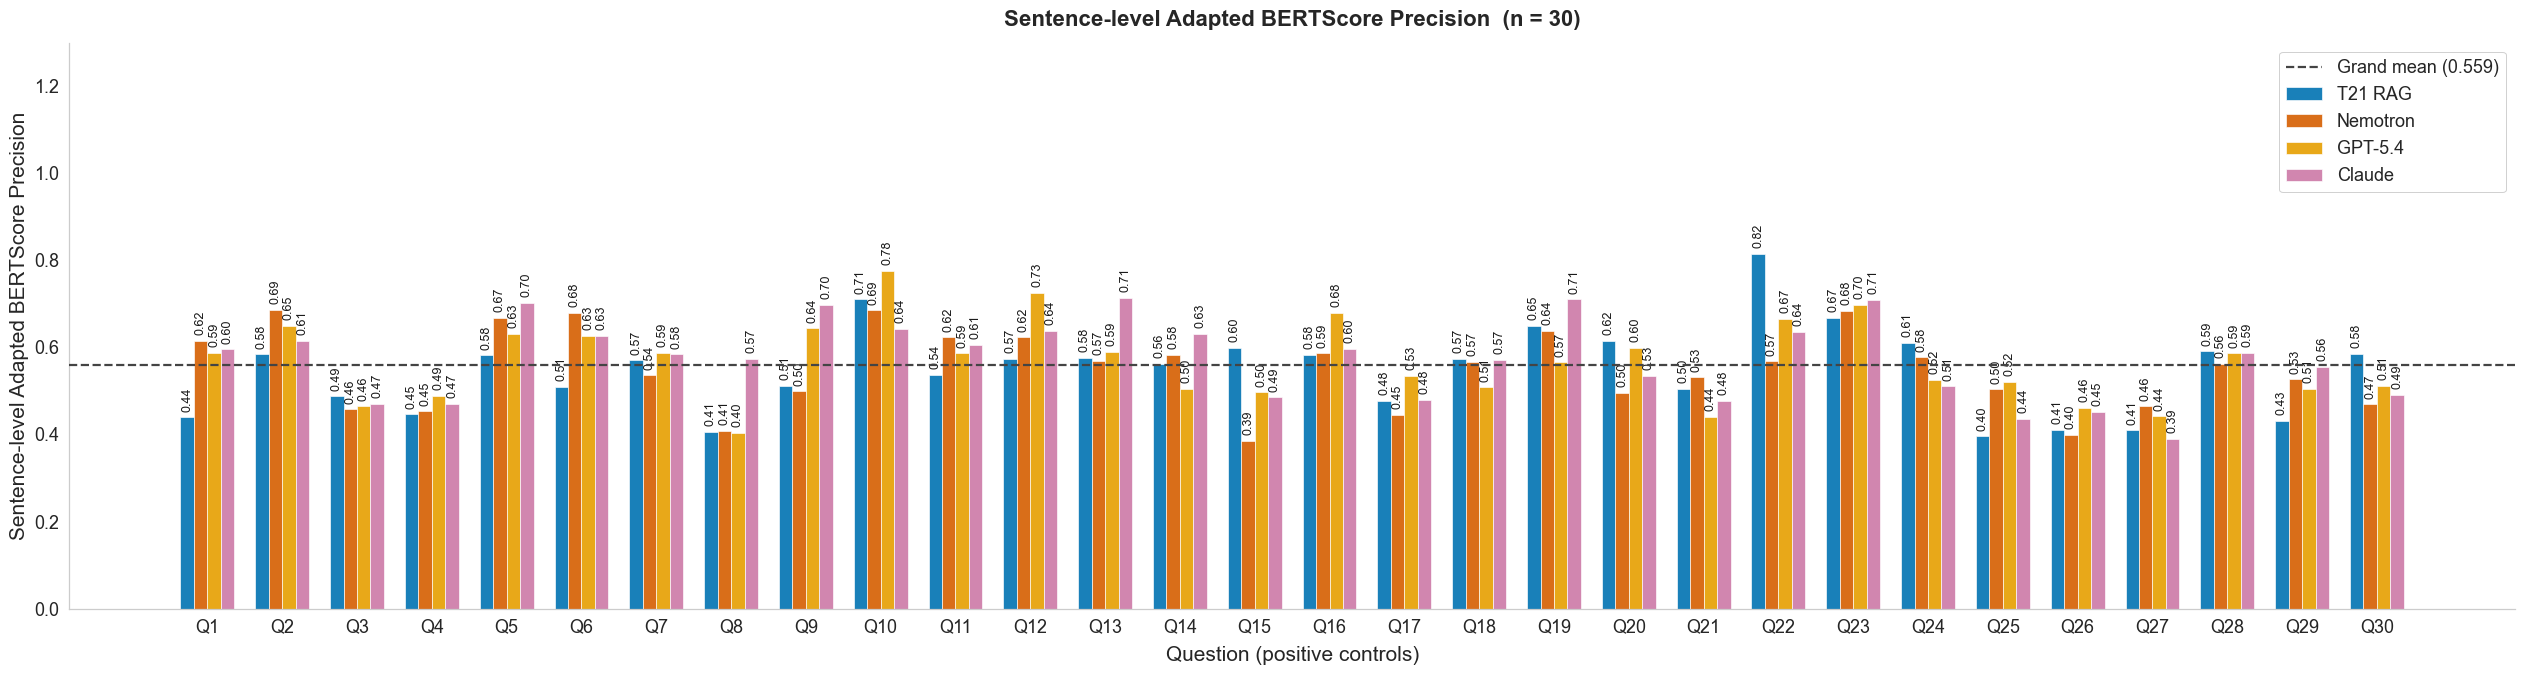

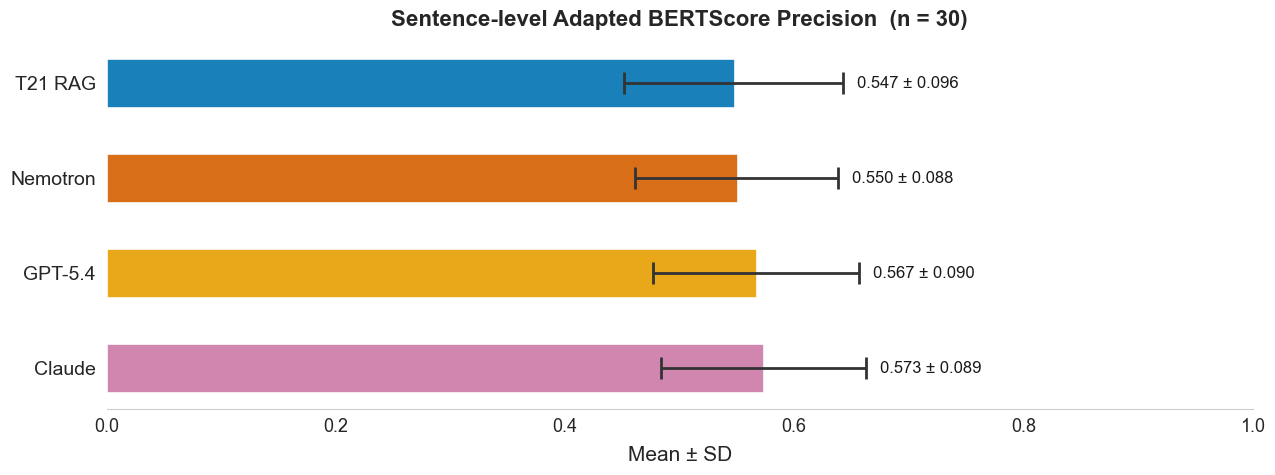

  Sentence-level Adapted BERTScore Precision:  T21=0.5471  Nem=0.5498  GPT=0.5669  Claude=0.5731
  Wilcoxon vs T21 (Bonferroni):  Nemotron p=1.0000 ns  |  GPT-5.4 p=0.6857 ns  |  Claude p=0.3259 ns



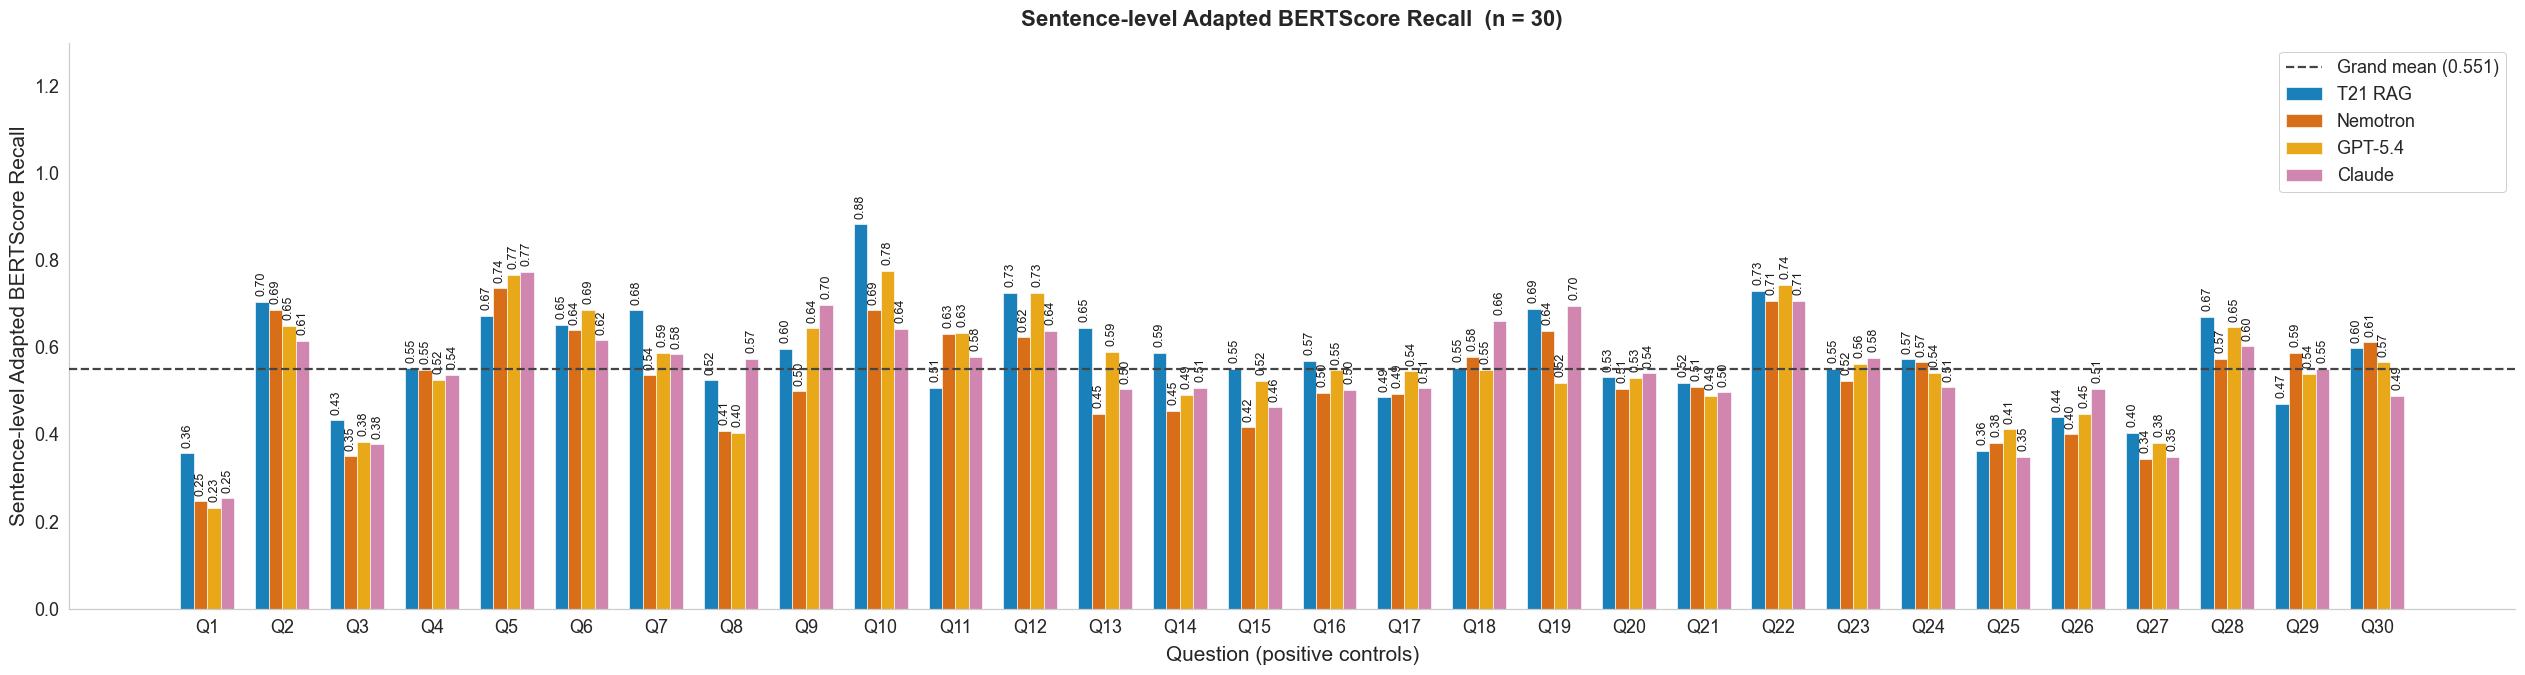

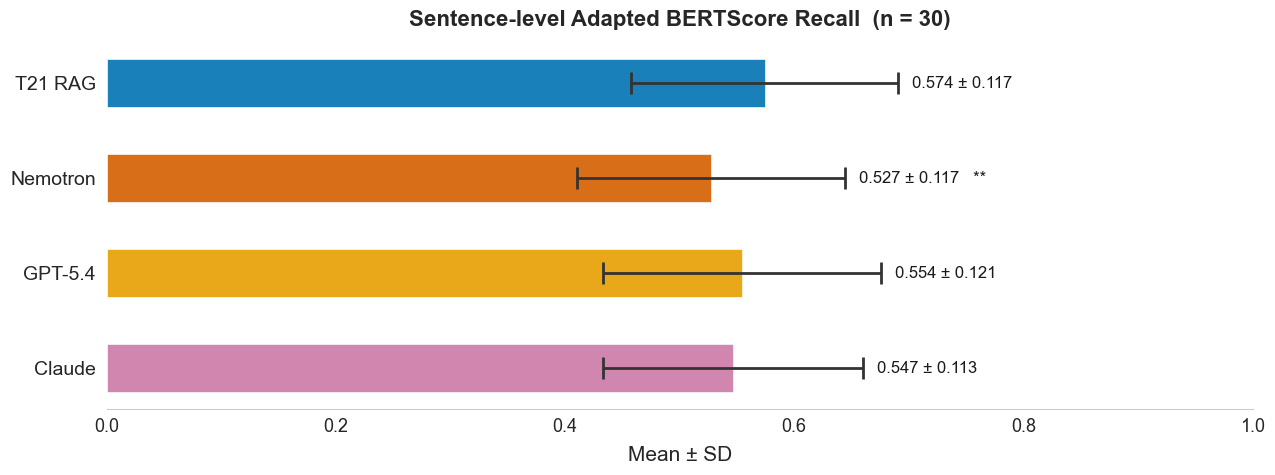

  Sentence-level Adapted BERTScore Recall:  T21=0.5741  Nem=0.5274  GPT=0.5545  Claude=0.5467
  Wilcoxon vs T21 (Bonferroni):  Nemotron p=0.0083 **  |  GPT-5.4 p=0.4042 ns  |  Claude p=0.2883 ns



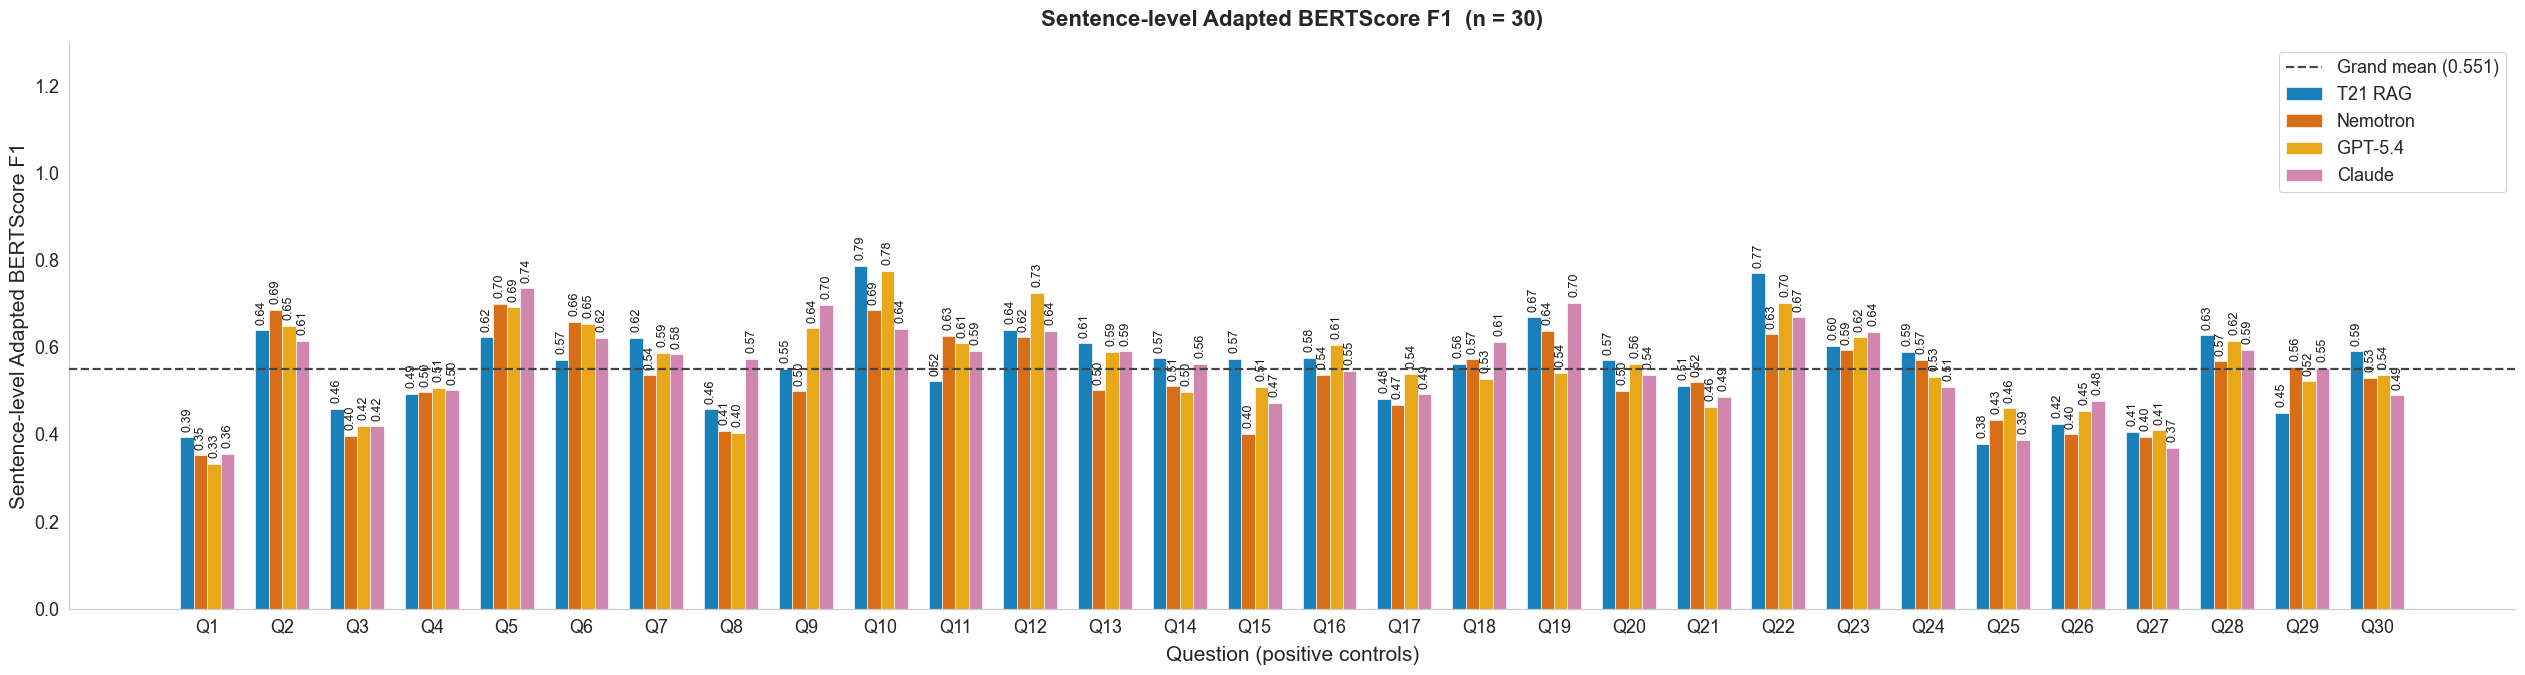

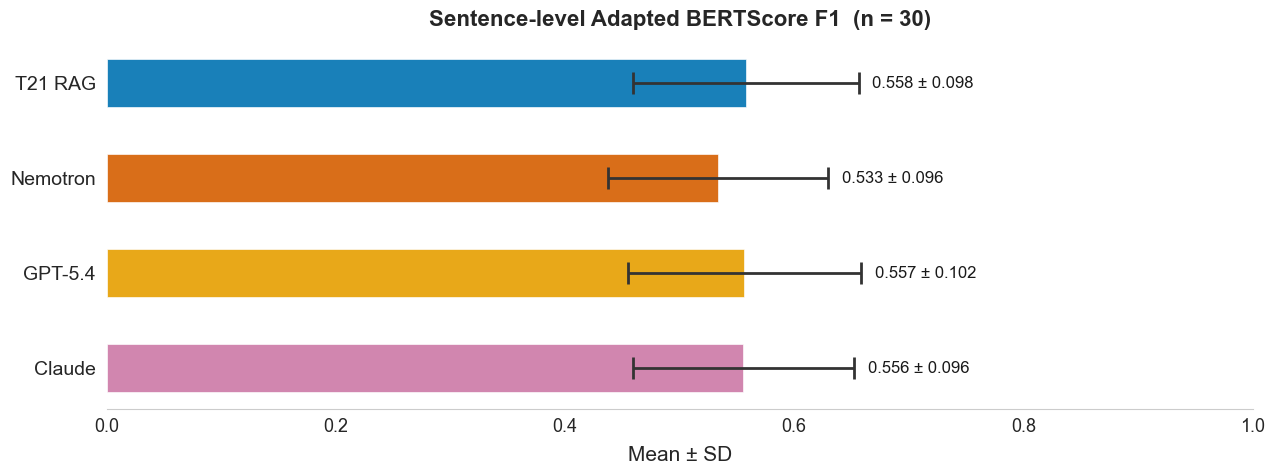

  Sentence-level Adapted BERTScore F1:  T21=0.5578  Nem=0.5332  GPT=0.5565  Claude=0.5557
  Wilcoxon vs T21 (Bonferroni):  Nemotron p=0.1280 ns  |  GPT-5.4 p=1.0000 ns  |  Claude p=1.0000 ns



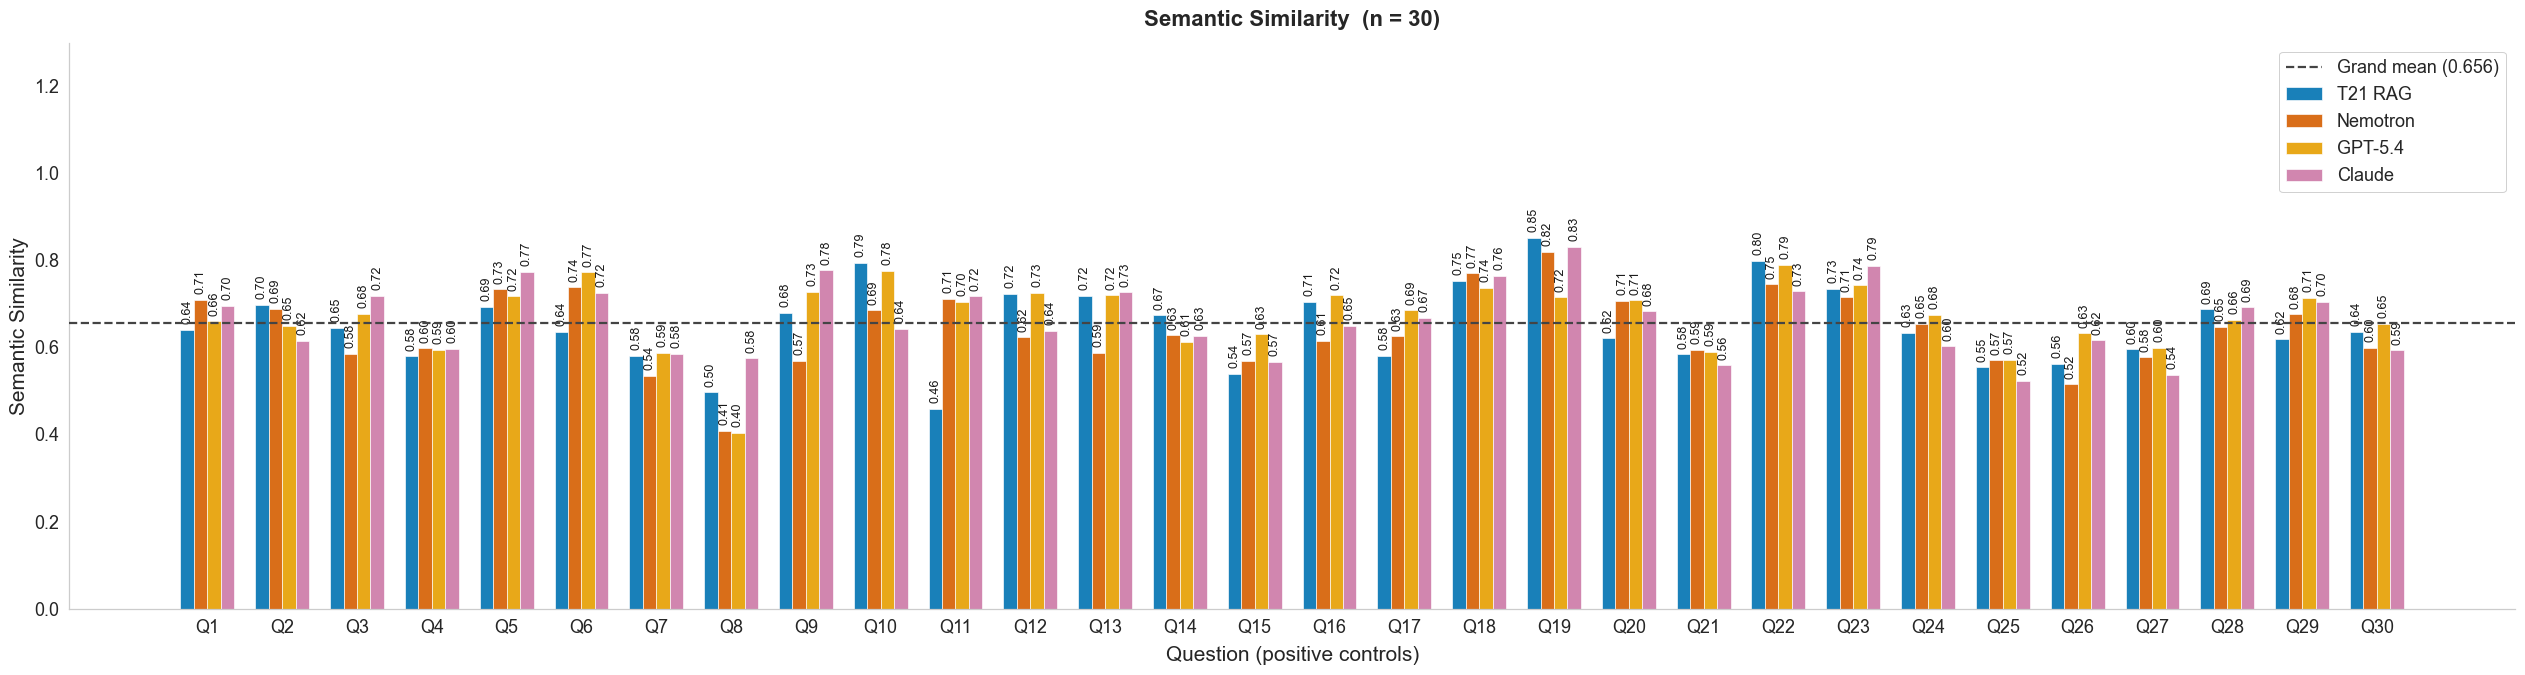

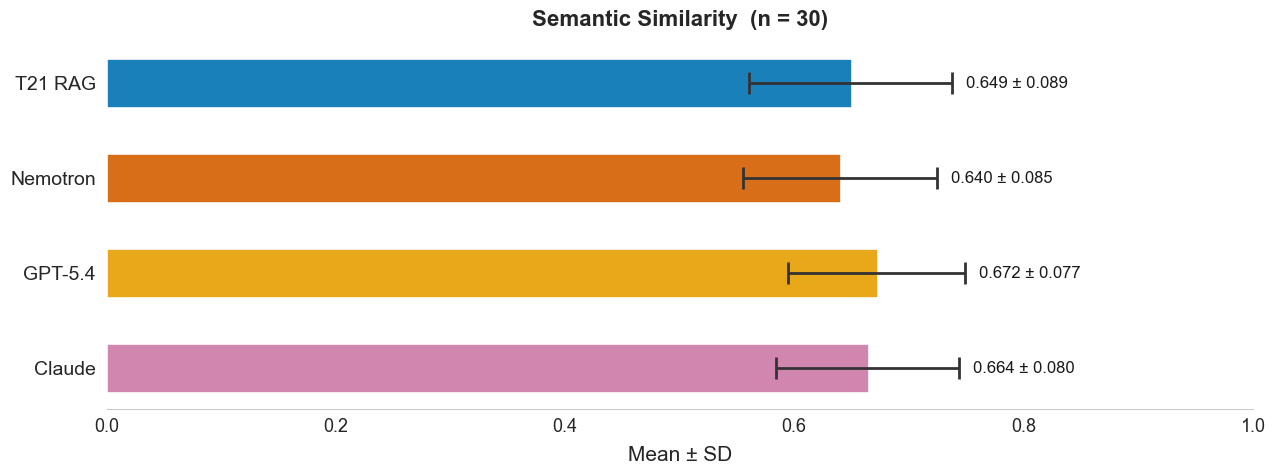

  Semantic Similarity:  T21=0.6493  Nem=0.6401  GPT=0.6720  Claude=0.6640
  Wilcoxon vs T21 (Bonferroni):  Nemotron p=0.7864 ns  |  GPT-5.4 p=0.1568 ns  |  Claude p=0.9552 ns



In [12]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import wilcoxon

# ── Nature/Science publication-quality style ───────────────────────────────────
matplotlib.rcParams.update({
    'font.family':           'sans-serif',
    'font.sans-serif':       ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size':             15,
    'axes.titlesize':        16,
    'axes.labelsize':        15,
    'xtick.labelsize':       13,
    'ytick.labelsize':       13,
    'legend.fontsize':       13,
    'legend.title_fontsize': 13,
    'figure.facecolor':      'white',
    'axes.facecolor':        'white',
    'axes.spines.top':       False,
    'axes.spines.right':     False,
    'axes.grid':             False,
    'pdf.fonttype':          42,
    'ps.fonttype':           42,
})

# ── Colour-blind-safe palette (Okabe–Ito derived) ─────────────────────────────
# Replaces the previous NPG palette, which paired Nemotron (crimson/red) with
# GPT-5.4 (emerald/green) in the same chart — reviewer feedback flagged this as
# both inaccessible to common color vision deficiencies and carrying an
# unintended "red=bad / green=good" connotation. No two colors below are a
# red/green pair.
NPG_M = {
    'T21 RAG':  '#0072B2',   # blue
    'Nemotron': '#D55E00',   # vermillion
    'GPT-5.4':  '#E69F00',   # orange
    'Claude':   '#CC79A7',   # reddish-purple
}
MODELS_M  = [('T21 RAG','t21'),('Nemotron','nemotron'),('GPT-5.4','gpt'),('Claude','claude')]
METRICS_M = [
    ('bertscore_p',  False, 'Sentence-level Adapted BERTScore Precision', 'bertscore_precision'),
    ('bertscore_r',  False, 'Sentence-level Adapted BERTScore Recall',    'bertscore_recall'),
    ('bertscore_f',  False, 'Sentence-level Adapted BERTScore F1',        'bertscore_f1'),
    ('semantic_sim', True,  'Semantic Similarity',                       'semantic_sim'),
]

# Raster export DPI — the per-question chart (Cell 9) below is bounded to a
# fixed 200 dpi for JPG/TIFF regardless of pixel-width. At n=30 questions the
# figure is capped at 26in wide (see figsize below); 26in x 200dpi = 5200px,
# which keeps JPG/TIFF file sizes reasonable (a few MB, not hundreds) while
# the PDF stays vector and fully print-crisp at any zoom. Previously a flat
# dpi=600 combined with an uncapped 1.8in/question width formula produced a
# 54in-wide raster (32,251 x 4,044 px, 130+ million pixels) — Python's own
# PIL flagged this as a potential decompression-bomb, and each TIFF was ~520MB
# (4 metrics = ~2GB total). The summary chart (fixed 13x5in) is small enough
# to keep the original 600 dpi.
_PERQ_DPI = {'pdf': 600, 'jpg': 200, 'tiff': 200}

def _getv(df, mdl, key, sem):
    col = f'semantic_sim_{mdl}' if sem else f'{mdl}_{key}'
    return df[col].values if col in df.columns else np.full(len(df), np.nan)

def _sig_label(p):
    """Return stars only for significant results; None otherwise."""
    if p is None or np.isnan(p): return None
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return None

def _wilcoxon_vs_t21(ref_vals, other_vals, n_comparisons=3):
    """Paired Wilcoxon signed-rank test; returns Bonferroni-corrected p-value."""
    valid = ~(np.isnan(ref_vals) | np.isnan(other_vals))
    if valid.sum() < 5:
        return float('nan')
    if np.all(ref_vals[valid] == other_vals[valid]):
        return 1.0
    try:
        _, p = wilcoxon(ref_vals[valid], other_vals[valid])
        return min(p * n_comparisons, 1.0)
    except Exception:
        return float('nan')

pos_all = df_bench[pos_mask].reset_index(drop=True)
n_q_m   = len(pos_all)
qlbls   = [f'Q{i+1}' for i in range(n_q_m)]
n_m_m   = len(MODELS_M)
bw_m    = 0.18
boffs_m = np.linspace(-(n_m_m-1)*bw_m/2, (n_m_m-1)*bw_m/2, n_m_m)
xq_m    = np.arange(n_q_m)

# === Per-metric figures: per-question bar + summary mean±SD bar ===============
# NOTE — significance stars: with the expanded n=30 positive-control benchmark
# (vs. n=12 previously), Wilcoxon tests may now have enough power to detect real
# differences. If a given metric shows no significant comparisons at all (every
# `pvals[lbl]` is None/ns), do not caption this panel as containing "significance
# annotations" in the manuscript — say plainly that no significant difference was
# found, per reviewer feedback on Figure 4.
for mkey, sem, panel_title, stem in METRICS_M:
    mdata = {lbl: _getv(pos_all, mdl, mkey, sem) for lbl, mdl in MODELS_M}

    # ── Wilcoxon tests: each model vs T21 RAG (Bonferroni, 3 comparisons) ───
    ref = mdata['T21 RAG']
    pvals = {lbl: None for lbl in mdata}
    for lbl in ['Nemotron', 'GPT-5.4', 'Claude']:
        pvals[lbl] = _wilcoxon_vs_t21(ref, mdata[lbl], n_comparisons=3)

    # ── per-question bar ──────────────────────────────────────────────────────
    # Width capped at 26in — the old uncapped 1.8in/question formula produced a
    # 54in-wide figure at n=30 (see _PERQ_DPI note above for why that broke).
    fg, ax = plt.subplots(figsize=(min(max(20, n_q_m*0.85), 26), 7))
    for off, (lbl, _) in zip(boffs_m, MODELS_M):
        ax.bar(xq_m+off, mdata[lbl], bw_m, label=lbl, color=NPG_M[lbl],
               alpha=0.90, edgecolor='white', linewidth=0.5)
    gm_i = float(np.nanmean(np.concatenate(list(mdata.values()))))
    ax.axhline(gm_i, color='#444444', linewidth=1.6, linestyle='--', zorder=4,
               label=f'Grand mean ({gm_i:.3f})')
    for off, (lbl, _) in zip(boffs_m, MODELS_M):
        for xi, v in zip(xq_m, mdata[lbl]):
            if not np.isnan(v):
                ax.text(xi+off, v+0.013, f'{v:.2f}', ha='center', va='bottom',
                        fontsize=9, color='#1a1a1a', rotation=90)
    ax.set_xticks(xq_m); ax.set_xticklabels(qlbls, fontsize=13)
    ax.set_ylim(0, 1.30)
    ax.set_xlabel('Question (positive controls)', fontsize=15, labelpad=7)
    ax.set_ylabel(panel_title, fontsize=15)
    ax.set_title(f'{panel_title}  (n = {n_q_m})',
                 fontweight='bold', fontsize=16, pad=12)
    leg = ax.legend(loc='upper right', framealpha=0.92, fontsize=13, edgecolor='#cccccc')
    leg.get_frame().set_linewidth(0.7)
    ax.spines['left'].set_linewidth(0.9); ax.spines['bottom'].set_linewidth(0.9)
    fg.tight_layout()
    for ext in ('pdf', 'jpg', 'tiff'):
        fg.savefig(str(OUTPUT_DIR / f'{stem}_per_question.{ext}'),
                   dpi=_PERQ_DPI[ext], bbox_inches='tight', facecolor='white')
    plt.show()

    # ── summary mean ± SD horizontal bar ─────────────────────────────────────
    fg2, ax2 = plt.subplots(figsize=(13, 5))
    lr   = [lbl for lbl, _ in reversed(MODELS_M)]   # Claude, GPT, Nemotron, T21 RAG
    mr   = [float(np.nanmean(mdata[lbl])) for lbl in lr]
    sr   = [float(np.nanstd(mdata[lbl]))  for lbl in lr]
    cr   = [NPG_M[lbl] for lbl in lr]
    yp2  = np.arange(len(lr))

    ax2.barh(yp2, mr, 0.50,
             xerr=sr,
             error_kw={'ecolor':'#333333','capsize':8,'elinewidth':2.0,'capthick':2.0},
             color=cr, alpha=0.90, edgecolor='white', linewidth=0.5)

    for yi2, lbl, v2, s2 in zip(yp2, lr, mr, sr):
        stars = _sig_label(pvals[lbl])
        label_str = f'{v2:.3f} ± {s2:.3f}   {stars}' if stars else f'{v2:.3f} ± {s2:.3f}'
        # clip_on=False so text beyond x=1.0 is not cut off
        ax2.text(v2+s2+0.012, yi2, label_str,
                 va='center', fontsize=12, color='#1a1a1a', clip_on=False)

    ax2.set_yticks(yp2); ax2.set_yticklabels(lr, fontsize=14)
    ax2.set_xlim(0.0, 1.0)
    ax2.set_xlabel('Mean ± SD', fontsize=15, labelpad=7)
    ax2.set_title(f'{panel_title}  (n = {n_q_m})',
                  fontweight='bold', fontsize=16, pad=12)
    ax2.spines['left'].set_visible(False)
    ax2.tick_params(axis='y', length=0, pad=8)
    ax2.tick_params(axis='x', labelsize=13)

    fg2.tight_layout()
    for ext in ('pdf', 'jpg', 'tiff'):
        fg2.savefig(str(OUTPUT_DIR / f'{stem}_summary.{ext}'),
                    dpi=600, bbox_inches='tight', facecolor='white')
    plt.show()

    # ── console summary ───────────────────────────────────────────────────────
    print(f'  {panel_title}:  T21={np.nanmean(mdata["T21 RAG"]):.4f}  '
          f'Nem={np.nanmean(mdata["Nemotron"]):.4f}  '
          f'GPT={np.nanmean(mdata["GPT-5.4"]):.4f}  '
          f'Claude={np.nanmean(mdata["Claude"]):.4f}')
    _p_str = '  |  '.join(
        f'{lbl} p={pvals[lbl]:.4f} {_sig_label(pvals[lbl]) or "ns"}'
        for lbl in ['Nemotron', 'GPT-5.4', 'Claude']
        if pvals[lbl] is not None and not np.isnan(pvals[lbl])
    )
    print(f'  Wilcoxon vs T21 (Bonferroni):  {_p_str}')
    print()
